# QUANT Interval-Selection Experiment Analysis

**How the numbers are built**

1. Only runs with `status == "ok"` are used, and only resamples that succeeded for **every** configuration (so every comparison is paired on identical train/test splits).
2. For each dataset × configuration × classifier, accuracy, feature count and timings are **averaged over the resamples** (timings can switch to the median with `TIME_AGG`).
3. Every configuration is compared to the baseline *within the same dataset*, giving per-dataset accuracy differences, relative error reduction, and feature/time reductions (positive = better than baseline).
4. Datasets are split into size groups (equal-count percentile bins) and into dataset types (Image, Sensor, Motion, ...), and the group analyses are repeated for both, to see where a configuration helps or hurts.

> Use a separate results CSV per configuration. The `run.py` resume key is dataset + resample + classifier, so sharing one output file across configurations can cause runs to be skipped.

# Experiment description

## What experiments are based on
Features in quant are taken as quantile values taken from intervals of the original datasets. Intervals of different sizes are taken for each dataset by taking intervals at different depths. At depth $d$ for any dataset sample, the number of intervals $I_n$ taken from the dataset is calculated as:
$$
I_{n} = d^2
$$
Where the length of each interval $I_n$ for a sample of length $n$ is:

$$
I_n = \frac{n}{2^d}
$$

In the original paper, shift intervals were also taken at each depth. These intervals had the same interval length as the original intervals at this depth, but one less it taken than in the normal intervals, and the interval start position are shifted by half an interval width, as shown below.

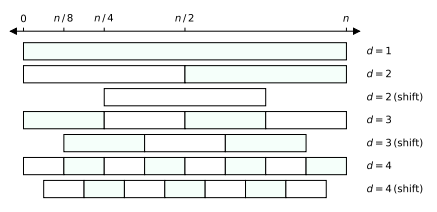

In the orignial paper, intervals were taken at every depth up to a maximum depth $D$ for a sample length $n$ calculated as follows:

$$
D = min(6, log_2 n + 1)
$$

## Experiments Conducted
These experiments involved reducing the number of intervals taken in the original paper by not calculating intervals or their quantile values as certian depths. These experiments conducted are described in the table below. This table also includes the extent of expriements conducted, and intial results.

| Experiment Name | Description | Experiments Conducted | Results |
| --------------- | ----------- | --------------------- | ------- |
| depths_0_5 | Baseline with the same intervals as the original | Ran for all datasets (142) and resamples (30) | N/a |
| no_depth_5 | This test took intervals at the same depths as the baseline without depth 5 intervals. This was done in the original paper and called $QUANT^{FAST}$ | Ran for all datasets (142) and resamples (30) | Minimal accuracy difference across dataset compared to baseline, deemed insignificant according to Friedman and Wilcoxon signed-rank testing and reduced feature count and training time |
| no_depth_4_5 | This test took intervals at the same depths as the baseline without depths 4 and 5 intervals | Ran for all datasets (142) and resamples (30) | Small accuracy difference across dataset compared to baseline, deemed significant according to to Friedman and Wilcoxon signed-rank testing but further reduced feature count and training time compared to origninal and $QUANT^{FAST}$ |
| even_depths | This test took intervals for every second depth value (0, 2, 4) to the same maximum as in the baseline | Ran for all datasets (142) and resamples (30) | Small accuracy difference across dataset compared to baseline, deemed significant according to to Friedman and Wilcoxon signed-rank testing but had the largest feature count and training time reduction compared to origninal and $QUANT^{FAST}$ |
| alternating_depths | This test took normal intervals for every second depth value (0, 2, 4) and shift intervals for every other depth value (1, 3, 5) to the same maximum as in the baseline | Ran for all datasets (142) and resamples (30) | Accuracy reduction across dataset compared to baseline, deemed significant according to to Friedman and Wilcoxon signed-rank testing. Although reasonable feature count and training time reduction, better results came from no_depths_4_5 (better accuracy) and even depths (larger feature reduction), so doesnt warrent further consideration |
| odd_depths | This test took intervals for every second depth value (1, 3, 5) to the same maximum as in the baseline | Ran for all datasets (142) and resamples (30) | Accuracy reduction across dataset compared to baseline, deemed significant according to to Friedman and Wilcoxon signed-rank testing. Although reasonable feature count and training time reduction, better accuracy and feature count reduction camde from other experiments so doesnt warrent further consideration |
| no_depth_0 | This test took intervals at the same depths as the baseline without depth 0 intervals | Ran for all datasets (142) and resamples (30) | Larger reduction in accuracy compared to baseline, deemed significant according to to Friedman and Wilcoxon signed-rank testing and didn't reduce feature count or training time substantially enough to warrent further consideration |
| no_depth_0_1 | This test took intervals at the same depths as the baseline without depths 0 or 1 intervals | Ran for all datasets (142) and resamples (30) | Largest reduction in accuracy compared to baseline, deemed significant according to to Friedman and Wilcoxon signed-rank testing and didn't reduce feature count or training time substantially enough to warrent further consideration |


Further analysis of results can be found at the end of this notebook.

## 1. Configuration

In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display
from scipy import stats

# --- Inputs -----------------------------------------------------------------
RESULTS_DIR = Path("../results")

# CSV filename stem -> display label. Each stem must have <RESULTS_DIR>/<stem>.csv
CONFIG_LABELS = {
    "depths_0_5_baseline": "Baseline (depths 0–5)",
    "no_depth_5": "Depth 5 excluded",
    "no_depth_4_5": "Depth 4 and 5 excluded",
    "alternating_depths": "Alternating normal/shift",
    "even_depths": "Even depths (0, 2, 4)",
    "odd_depths": "Odd depths (1, 3, 5)",
    "no_depth_0": "Depth 0 excluded",
    "no_depth_0_1": "Depth 0 and 1 excluded"
}
BASELINE = "Baseline (depths 0–5)"   # must be one of the labels above

CLASSIFIERS = None                    # e.g. ["extratrees"]; None = all found in the CSVs

# --- Aggregation / statistics -----------------------------------------------
TIME_AGG = "mean"                     # how timings are combined over resamples: "mean" or "median"
TIE_TOL = 1e-12                       # |accuracy difference| below this counts as a tie
N_BOOTSTRAP = 5000                    # bootstrap resamples for the mean-difference confidence interval
ERROR_EPS = 0.001                     # pseudo-error added to BOTH errors in the smoothed error ratio (0.001 = 0.1 pp)
                                      # ideally ~0.5 / n_test; try 0.0005 and 0.002 to check the conclusions do not change
SEED = 0

# --- Dataset-size groups ----------------------------------------------------
N_SIZE_GROUPS = 5                     # equal-count percentile bins (5 = quintiles)
# Optional CSV with one row per dataset: dataset, n_train, series_length[, n_channels]
# (or a single precomputed `size` column). If None, the notebook looks for such
# columns in the results CSVs, and otherwise falls back to a runtime-based proxy.
SIZE_METADATA_CSV = None              # e.g. Path("../dataset_metadata.csv")

# --- Dataset types ----------------------------------------------------------
TYPES_CSV = Path("../improvedQuant/dataSetLists/dataset_types.csv")   # one row per dataset: dataset, type, type_group, ...
TYPE_COLUMN = "type_group"            # "type_group" (rare types merged into Other) or "type" (original archive types)
MIN_DATASETS_PER_GROUP = 8            # groups with fewer datasets get no CD diagram

print("Results directory:", RESULTS_DIR.resolve())

Results directory: C:\Users\davyt\quant-reproduction\results


## 2. Load and validate

Missing or malformed files are reported rather than silently skipped, and the notebook stops if the baseline is not available.

In [20]:
REQUIRED = {
    "dataset", "resample", "classifier", "accuracy", "status", "n_features",
    "time_transform_train", "time_fit", "time_transform_test", "time_predict",
}
NUMERIC = [
    "accuracy", "balanced_accuracy", "n_features",
    "time_transform_train", "time_fit", "time_transform_test", "time_predict",
]

frames, load_issues = [], []
for stem, label in CONFIG_LABELS.items():
    path = RESULTS_DIR / f"{stem}.csv"
    try:
        frame = pd.read_csv(path)
    except Exception as exc:
        load_issues.append({"file": str(path), "issue": f"Could not read: {exc}"})
        continue
    missing = sorted(REQUIRED - set(frame.columns))
    if missing:
        load_issues.append({"file": str(path), "issue": "Missing columns: " + ", ".join(missing)})
        continue
    frame["configuration"] = label
    for col in NUMERIC:
        frame[col] = pd.to_numeric(frame[col], errors="coerce") if col in frame else np.nan
    frame["resample"] = pd.to_numeric(frame["resample"], errors="coerce")
    frame["status"] = frame["status"].fillna("").astype(str)
    frames.append(frame)

if load_issues:
    display(pd.DataFrame(load_issues))
if not frames:
    raise FileNotFoundError("No usable result CSVs found. Check RESULTS_DIR and CONFIG_LABELS.")

results = pd.concat(frames, ignore_index=True, sort=False)
if BASELINE not in set(results["configuration"]):
    raise ValueError(f"Baseline '{BASELINE}' was not loaded. Loaded: {sorted(results['configuration'].unique())}")
if CLASSIFIERS is not None:
    results = results[results["classifier"].isin(CLASSIFIERS)].copy()

# Duplicated runs would double-count a resample, so keep the first and say so.
run_key = ["configuration", "dataset", "classifier", "resample"]
n_dup = int(results.duplicated(run_key).sum())
if n_dup:
    print(f"WARNING: dropped {n_dup} duplicated runs (same configuration/dataset/classifier/resample).")
    results = results.drop_duplicates(run_key, keep="first")

results["is_success"] = results["status"].str.lower().eq("ok") & results["accuracy"].notna()

print(f"Loaded {len(results):,} runs from {len(frames)} file(s); "
      f"{int(results['is_success'].sum()):,} successful.")
display(
    results.groupby(["configuration", "classifier", "status"]).size()
    .rename("runs").reset_index()
)

Loaded 34,080 runs from 8 file(s); 34,080 successful.


,configuration,classifier,status,runs
0,Alternating normal/shift,extratrees,ok,4260
1,Baseline (depths 0–5),extratrees,ok,4260
2,Depth 0 and 1 excluded,extratrees,ok,4260
3,Depth 0 excluded,extratrees,ok,4260
4,Depth 4 and 5 excluded,extratrees,ok,4260
5,Depth 5 excluded,extratrees,ok,4260
6,"Even depths (0, 2, 4)",extratrees,ok,4260
7,"Odd depths (1, 3, 5)",extratrees,ok,4260


## 3. Paired runs and per-dataset averages

A resample is kept only if the same dataset/classifier/resample succeeded in **all** configurations, so every configuration is averaged over the same splits. The table `table` has one row per dataset × configuration × classifier and is used by everything below.

In [21]:
ok = results.loc[results["is_success"]].copy()
ok["time_train_total"] = ok["time_transform_train"] + ok["time_fit"]
ok["time_test_total"] = ok["time_transform_test"] + ok["time_predict"]

# Keep only resamples that succeeded in every configuration.
all_configs = sorted(ok["configuration"].unique())
pair_key = ["dataset", "classifier", "resample"]
n_cfg = ok.groupby(pair_key)["configuration"].transform("nunique")
paired = ok.loc[n_cfg == len(all_configs)].copy()
print(f"Configurations: {all_configs}")
print(f"Successful runs: {len(ok):,} -> kept {len(paired):,} runs in complete resample sets "
      f"({len(ok) - len(paired):,} dropped).")

TIME_COLS = ["time_transform_train", "time_fit", "time_transform_test", "time_predict",
             "time_train_total", "time_test_total"]
agg_spec = {
    "accuracy": ("accuracy", "mean"),
    "balanced_accuracy": ("balanced_accuracy", "mean"),
    "n_features": ("n_features", "mean"),
    "n_resamples": ("resample", "nunique"),
}
agg_spec.update({c: (c, TIME_AGG) for c in TIME_COLS})

table = (
    paired.groupby(["dataset", "classifier", "configuration"], as_index=False)
    .agg(**agg_spec)
)
table["error"] = 1 - table["accuracy"]

# Coverage check: every dataset should appear in every configuration with the same resample count.
cov = table.groupby(["classifier", "configuration"]).agg(
    datasets=("dataset", "nunique"),
    resamples_min=("n_resamples", "min"),
    resamples_median=("n_resamples", "median"),
    resamples_max=("n_resamples", "max"),
)
display(cov)
print(f"{table['dataset'].nunique()} datasets in the analysis table.")

Configurations: ['Alternating normal/shift', 'Baseline (depths 0–5)', 'Depth 0 and 1 excluded', 'Depth 0 excluded', 'Depth 4 and 5 excluded', 'Depth 5 excluded', 'Even depths (0, 2, 4)', 'Odd depths (1, 3, 5)']
Successful runs: 34,080 -> kept 34,080 runs in complete resample sets (0 dropped).


datasets  resamples_min  resamples_median  resamples_max
classifier configuration                                                                     
extratrees Alternating normal/shift       142             30              30.0             30
           Baseline (depths 0–5)          142             30              30.0             30
           Depth 0 and 1 excluded         142             30              30.0             30
           Depth 0 excluded               142             30              30.0             30
           Depth 4 and 5 excluded         142             30              30.0             30
           Depth 5 excluded               142             30              30.0             30
           Even depths (0, 2, 4)          142             30              30.0             30
           Odd depths (1, 3, 5)           142             30              30.0             30

142 datasets in the analysis table.


## 4. Dataset-size groups

QUANT's cost scales with the number of training cases × series length × channels, so that is the preferred size measure. The notebook uses, in order:

1. `SIZE_METADATA_CSV` (or columns in the results CSVs) with `n_train` and `series_length` (and optionally `n_channels`);
2. a single `size` column, if present;
3. otherwise a **runtime proxy**: the geometric mean of `time_transform_train` across configurations. This is a reasonable stand-in for data volume, but it is measured, so noisy timings can nudge a dataset into a neighbouring group. Use real metadata for anything you plan to publish.

Groups are equal-count percentile bins (`N_SIZE_GROUPS`), so each group has roughly the same number of datasets.

In [22]:
SIZE_ALIASES = {
    "n_train": ["n_train", "n_train_cases", "n_cases_train", "train_size"],
    "length": ["series_length", "n_timepoints", "n_timesteps", "length"],
    "channels": ["n_channels", "n_dimensions", "n_dims"],
    "size": ["size", "dataset_size"],
}

def find_col(df, key):
    return next((c for c in SIZE_ALIASES[key] if c in df.columns), None)

def size_from_frame(df):
    # Return (Series indexed by dataset, description) or None if no usable columns.
    per_dataset = df.groupby("dataset").first()
    n_train, length, chans = (find_col(per_dataset, k) for k in ("n_train", "length", "channels"))
    if n_train and length:
        size = per_dataset[n_train] * per_dataset[length]
        if chans:
            size = size * per_dataset[chans].fillna(1)
        return size, "n_train × series_length" + (" × n_channels" if chans else "")
    size_col = find_col(per_dataset, "size")
    if size_col:
        return per_dataset[size_col], size_col
    return None

size_info = None
if SIZE_METADATA_CSV is not None:
    size_info = size_from_frame(pd.read_csv(SIZE_METADATA_CSV))
    if size_info is None:
        raise ValueError("SIZE_METADATA_CSV needs n_train + series_length columns, or a `size` column.")
if size_info is None:
    size_info = size_from_frame(results)

if size_info is not None:
    dataset_size, SIZE_DESC = size_info
    dataset_size = dataset_size.reindex(table["dataset"].unique())
    if dataset_size.isna().any():
        raise ValueError(f"No size for datasets: {list(dataset_size.index[dataset_size.isna()])[:10]}")
else:
    SIZE_DESC = "runtime proxy (geometric mean of training-transform time, s)"
    dataset_size = (
        table.groupby("dataset")["time_transform_train"]
        .apply(lambda s: float(np.exp(np.log(s.clip(lower=1e-9)).mean())))
    )
    print("NOTE: no dataset-size metadata found, using a runtime proxy for size groups.")

dataset_size = dataset_size.astype(float).sort_values()
# Rank first so ties can't collapse bins; groups end up equal-sized (±1 dataset).
bin_id = pd.qcut(dataset_size.rank(method="first"), N_SIZE_GROUPS, labels=False)

group_label = {}
for g in range(N_SIZE_GROUPS):
    members = dataset_size[bin_id == g]
    lo_pct, hi_pct = round(100 * g / N_SIZE_GROUPS), round(100 * (g + 1) / N_SIZE_GROUPS)
    group_label[g] = f"G{g + 1}: {lo_pct}–{hi_pct}th pct  (size {members.min():.3g}–{members.max():.3g}, n={len(members)})"

GROUP_ORDER = [group_label[g] for g in range(N_SIZE_GROUPS)]
dataset_group = bin_id.map(group_label)
table["size_group"] = pd.Categorical(table["dataset"].map(dataset_group), categories=GROUP_ORDER, ordered=True)

print("Size measure:", SIZE_DESC)
display(dataset_group.value_counts().reindex(GROUP_ORDER).rename("datasets").rename_axis("size group").to_frame())

NOTE: no dataset-size metadata found, using a runtime proxy for size groups.
Size measure: runtime proxy (geometric mean of training-transform time, s)


,datasets
size group,
"G1: 0–20th pct (size 0.00977–0.0582, n=29)",29
"G2: 20–40th pct (size 0.0587–0.08, n=28)",28
"G3: 40–60th pct (size 0.0836–0.134, n=28)",28
"G4: 60–80th pct (size 0.135–0.207, n=28)",28
"G5: 80–100th pct (size 0.239–1.76, n=29)",29


## 4b. Dataset types

Datasets are also grouped by **type** (Image, Sensor, Motion, Device, ECG, Simulated, Spectro, ...), using the types from the UCR/TSC archive. `dataset_types.csv` has one row per dataset with the original archive `type` and a coarser `type_group`, in which the rare types (EOG, EPG, HRM, Hemodynamics, Power, Spectrum, Traffic, Trajectory) are merged into **Other** so every group has enough datasets to analyse. Set `TYPE_COLUMN = "type"` to use the original types instead.

Names ending in `_eq` (equal-length versions of unequal-length datasets) are matched to the base dataset name. Datasets that are not in the CSV are grouped as **Unknown** and listed below so you can add them.

Every group analysis below (sections 6b, 6c, 9, 10a, 10b) runs once per grouping in `GROUPINGS`: dataset size and dataset type.

In [23]:
types_df = pd.read_csv(TYPES_CSV)
type_map = dict(zip(types_df["dataset"], types_df[TYPE_COLUMN]))

def lookup_type(name):
    base = name[:-3] if name.endswith("_eq") else name
    return type_map.get(name, type_map.get(base, "Unknown"))

dataset_type = pd.Series({d: lookup_type(d) for d in table["dataset"].unique()})
unknown = sorted(dataset_type.index[dataset_type == "Unknown"])
if unknown:
    print(f"{len(unknown)} dataset(s) not found in {TYPES_CSV.name} (grouped as 'Unknown'; add them to the CSV):")
    print(", ".join(unknown))

counts_by_type = dataset_type.value_counts()
# Largest types first; "Other" and "Unknown" last.
TYPE_NAMES = (
    [t for t in counts_by_type.index if t not in ("Other", "Unknown")]
    + [t for t in ("Other", "Unknown") if t in counts_by_type.index]
)
type_label = {t: f"{t} (n={counts_by_type[t]})" for t in TYPE_NAMES}
TYPE_ORDER = [type_label[t] for t in TYPE_NAMES]
dataset_type_group = dataset_type.map(type_label)
table["type_group"] = pd.Categorical(table["dataset"].map(dataset_type_group), categories=TYPE_ORDER, ordered=True)

# Every group analysis below runs once per grouping: label -> (column in the tables, ordered group names).
GROUPINGS = {
    "size group": ("size_group", GROUP_ORDER),
    "dataset type": ("type_group", TYPE_ORDER),
}
dataset_groups = {"size_group": dataset_group, "type_group": dataset_type_group}   # column -> (dataset -> group name)

small = [t for t in TYPE_NAMES if counts_by_type[t] < MIN_DATASETS_PER_GROUP]
if small:
    print(f"Note: types with fewer than {MIN_DATASETS_PER_GROUP} datasets get no CD diagram: {small}")
display(counts_by_type.reindex(TYPE_NAMES).rename("datasets").rename_axis("type").to_frame())

19 dataset(s) not found in dataset_types.csv (grouped as 'Unknown'; add them to the CSV):
AconityMINIPrinterLarge_eq, AconityMINIPrinterSmall_eq, AsphaltObstaclesUni_eq, AsphaltPavementTypeUni_eq, AsphaltRegularityUni_eq, Colposcopy, Covid3Month_disc, DodgerLoopDay_nmv, DodgerLoopGame_nmv, DodgerLoopWeekend_nmv, ElectricDeviceDetection, FloodModeling1_disc, FloodModeling2_disc, FloodModeling3_disc, KeplerLightCurves, MelbournePedestrian_nmv, PhoneHeartbeatSound, SharePriceIncrease, Tools
Note: types with fewer than 8 datasets get no CD diagram: ['ECG']


,datasets
type,
Image,32
Sensor,27
Motion,17
Device,9
Simulated,8
Spectro,8
ECG,6
Other,16
Unknown,19


## 5. Per-dataset comparison with the baseline

For each non-baseline configuration and dataset (all values positive = better than baseline unless noted):

- **Accuracy difference** (percentage points): $\Delta A = A_{\text{new}} - A_{\text{baseline}}$
- **Relative error reduction** (%): $\dfrac{E_{\text{baseline}} - E_{\text{new}}}{E_{\text{baseline}}}$, where $E = 1 - A$. This is **undefined when the baseline error is 0** (a perfect baseline), so those datasets are left out of this one metric (reported below) instead of producing `-inf`/`NaN`.
- **Smoothed error ratio**: $\dfrac{E_{\text{new}} + \varepsilon}{E_{\text{baseline}} + \varepsilon}$ with a small pseudo-error $\varepsilon$ (`ERROR_EPS`) added to both errors, averaged on the log scale (geometric mean). Unlike relative error reduction it is defined for perfect baselines and cannot be dominated by one or two test-case errors on a near-perfect dataset. 1.0 = no change, 1.2 = 20% more error.
- **Feature, training-time and test-time reduction** (%): $\dfrac{X_{\text{baseline}} - X_{\text{new}}}{X_{\text{baseline}}}$. Training time is `time_transform_train + time_fit`; test time is `time_transform_test + time_predict`.

In [24]:
BASE_COLS = ["accuracy", "error", "n_features", "time_train_total", "time_test_total"]

base = (
    table.loc[table["configuration"] == BASELINE]
    .set_index(["dataset", "classifier"])[BASE_COLS]
    .add_prefix("base_")
)
cmp = table.loc[table["configuration"] != BASELINE].join(base, on=["dataset", "classifier"])
cmp = cmp.dropna(subset=["base_accuracy"]).copy()

def pct_reduction(new, old):
    return 100 * (old - new) / old.where(old > 0)      # NaN where the baseline value is 0

cmp["acc_diff_pp"] = 100 * (cmp["accuracy"] - cmp["base_accuracy"])
cmp["error_reduction_pct"] = pct_reduction(cmp["error"], cmp["base_error"])
# Smoothed error ratio: the pseudo-error ERROR_EPS stops one or two test-case errors on a near-perfect
# baseline from producing a huge ratio. log2 makes "doubled" (+1) and "halved" (-1) symmetric.
cmp["log2_error_ratio"] = np.log2((cmp["error"] + ERROR_EPS) / (cmp["base_error"] + ERROR_EPS))
cmp["feature_reduction_pct"] = pct_reduction(cmp["n_features"], cmp["base_n_features"])
cmp["train_time_reduction_pct"] = pct_reduction(cmp["time_train_total"], cmp["base_time_train_total"])
cmp["test_time_reduction_pct"] = pct_reduction(cmp["time_test_total"], cmp["base_time_test_total"])

excluded = (
    cmp.assign(perfect_baseline=cmp["base_error"] <= 0)
    .groupby(["classifier", "configuration"])["perfect_baseline"].sum()
    .rename("datasets excluded from error reduction (baseline accuracy = 100%)")
)
display(excluded.to_frame())

COMPARE_CONFIGS = sorted(cmp["configuration"].unique())
palette = plt.get_cmap("tab10")
CONFIG_COLORS = {BASELINE: "#7f7f7f"}
CONFIG_COLORS.update({c: palette(i) for i, c in enumerate(COMPARE_CONFIGS)})
classifiers = sorted(table["classifier"].unique())

datasets excluded from error reduction (baseline accuracy = 100%)
classifier configuration                                                                              
extratrees Alternating normal/shift                                                  5                
           Depth 0 and 1 excluded                                                    5                
           Depth 0 excluded                                                          5                
           Depth 4 and 5 excluded                                                    5                
           Depth 5 excluded                                                          5                
           Even depths (0, 2, 4)                                                     5                
           Odd depths (1, 3, 5)                                                      5

## 6. Summary statistics

Each row summarises one configuration against the baseline across datasets. Besides means and medians it reports:

- **improved / tied / declined**: datasets where the (averaged) accuracy went up, stayed within `TIE_TOL`, or went down;
- **95% CI**: bootstrap confidence interval for the mean accuracy difference (resampling datasets);
- **Wilcoxon p**: paired two-sided signed-rank test on the per-dataset accuracy differences (ties dropped). With several configurations and size groups you are making many comparisons, so treat isolated small p-values with caution and prefer the CI and the effect size.

In [25]:
rng = np.random.default_rng(SEED)

def bootstrap_ci(values, n_boot=N_BOOTSTRAP, alpha=0.05):
    values = np.asarray(values, dtype=float)
    if len(values) < 2:
        return np.nan, np.nan
    idx = rng.integers(0, len(values), size=(n_boot, len(values)))
    means = values[idx].mean(axis=1)
    return tuple(np.quantile(means, [alpha / 2, 1 - alpha / 2]))

def wilcoxon_p(diffs):
    nonzero = diffs[np.abs(diffs) > TIE_TOL]
    if len(nonzero) < 6:                      # too few non-tied datasets for a meaningful test
        return np.nan
    return stats.wilcoxon(nonzero).pvalue

def summarise(frame, group_cols):
    rows = []
    for keys, g in frame.groupby(group_cols, observed=True):
        keys = keys if isinstance(keys, tuple) else (keys,)
        d = g["acc_diff_pp"].to_numpy()
        diff_frac = d / 100
        ci_lo, ci_hi = bootstrap_ci(d)
        rows.append({
            **dict(zip(group_cols, keys)),
            "datasets": len(g),
            "acc diff mean (pp)": d.mean(),
            "95% CI": f"[{ci_lo:.2f}, {ci_hi:.2f}]",
            "acc diff median (pp)": np.median(d),
            "improved": int((diff_frac > TIE_TOL).sum()),
            "tied": int((np.abs(diff_frac) <= TIE_TOL).sum()),
            "declined": int((diff_frac < -TIE_TOL).sum()),
            "Wilcoxon p": wilcoxon_p(diff_frac),
            "error red. mean (%)": g["error_reduction_pct"].mean(),
            "error red. median (%)": g["error_reduction_pct"].median(),
            "error red. n": int(g["error_reduction_pct"].notna().sum()),
            "smoothed error ratio (geo. mean)": 2 ** g["log2_error_ratio"].mean(),
            "feature red. mean (%)": g["feature_reduction_pct"].mean(),
            "train time red. mean (%)": g["train_time_reduction_pct"].mean(),
            "train time red. median (%)": g["train_time_reduction_pct"].median(),
            "test time red. mean (%)": g["test_time_reduction_pct"].mean(),
            "test time red. median (%)": g["test_time_reduction_pct"].median(),
        })
    return pd.DataFrame(rows)

def show(summary):
    pd.set_option("display.width", 250, "display.max_columns", None)
    display(
        summary.style.format(
            {c: "{:.2f}" for c in summary.columns if c.endswith(("(pp)", "(%)"))} | {"Wilcoxon p": "{:.4f}"},
            na_rep="–",
        ).hide(axis="index")
    )

### 6a. Overall (all datasets)

In [26]:
overall = summarise(cmp, ["classifier", "configuration"])
show(overall)

classifier,configuration,datasets,acc diff mean (pp),95% CI,acc diff median (pp),improved,tied,declined,Wilcoxon p,error red. mean (%),error red. median (%),error red. n,smoothed error ratio (geo. mean),feature red. mean (%),train time red. mean (%),train time red. median (%),test time red. mean (%),test time red. median (%)
extratrees,Alternating normal/shift,142,-0.25,"[-0.34, -0.17]",-0.21,30,5,107,0.0000,-7.14,-2.35,137,1.044773,46.99,28.29,27.45,40.25,40.71
extratrees,Depth 0 and 1 excluded,142,-0.95,"[-1.55, -0.50]",-0.20,42,4,96,0.0000,-40.73,-2.73,137,1.108952,23.43,10.32,10.07,12.80,12.13
extratrees,Depth 0 excluded,142,-0.32,"[-0.51, -0.16]",-0.03,55,10,77,0.0005,-7.60,-0.60,137,1.030628,9.35,3.56,4.45,4.65,3.82
extratrees,Depth 4 and 5 excluded,142,-0.23,"[-0.43, -0.06]",-0.02,58,6,78,0.0302,-4.83,-0.52,137,1.040816,41.13,28.89,26.94,44.07,44.65
extratrees,Depth 5 excluded,142,-0.05,"[-0.13, 0.02]",0.00,67,11,64,0.3439,-0.10,0.00,137,1.009953,21.17,16.58,16.94,26.02,25.94
extratrees,"Even depths (0, 2, 4)",142,-0.23,"[-0.35, -0.13]",-0.10,57,5,80,0.0001,-11.20,-0.97,137,1.045674,53.98,33.10,31.62,48.18,48.77
extratrees,"Odd depths (1, 3, 5)",142,-0.43,"[-0.57, -0.31]",-0.25,33,6,103,0.0000,-11.16,-2.86,137,1.059151,46.02,23.49,20.05,32.64,33.11


### 6b. By group (dataset size and dataset type)

In [27]:
for grouping, (col, order) in GROUPINGS.items():
    print(f"\n=== By {grouping} ===")
    show(summarise(cmp, ["classifier", col, "configuration"]))


=== By size group ===


classifier,size_group,configuration,datasets,acc diff mean (pp),95% CI,acc diff median (pp),improved,tied,declined,Wilcoxon p,error red. mean (%),error red. median (%),error red. n,smoothed error ratio (geo. mean),feature red. mean (%),train time red. mean (%),train time red. median (%),test time red. mean (%),test time red. median (%)
extratrees,"G1: 0–20th pct (size 0.00977–0.0582, n=29)",Alternating normal/shift,29,-0.15,"[-0.35, 0.03]",-0.10,6,2,21,0.0436,-17.92,-3.57,27,1.075629,46.31,13.23,13.77,34.73,37.27
extratrees,"G1: 0–20th pct (size 0.00977–0.0582, n=29)",Depth 0 and 1 excluded,29,-0.41,"[-0.72, -0.11]",-0.32,10,2,17,0.0229,-94.78,-14.49,27,1.197128,23.05,2.55,3.68,10.24,11.44
extratrees,"G1: 0–20th pct (size 0.00977–0.0582, n=29)",Depth 0 excluded,29,-0.08,"[-0.26, 0.09]",0.00,14,5,10,0.8553,-2.53,0.99,27,1.011938,9.18,1.00,-1.87,4.14,2.36
extratrees,"G1: 0–20th pct (size 0.00977–0.0582, n=29)",Depth 4 and 5 excluded,29,-0.31,"[-0.57, -0.08]",-0.10,8,2,19,0.0229,-11.71,-3.57,27,1.108594,40.05,17.29,19.89,37.39,42.30
extratrees,"G1: 0–20th pct (size 0.00977–0.0582, n=29)",Depth 5 excluded,29,-0.08,"[-0.20, 0.03]",0.00,10,6,13,0.1793,2.63,0.00,27,1.017817,20.12,10.76,12.14,22.64,23.89
extratrees,"G1: 0–20th pct (size 0.00977–0.0582, n=29)","Even depths (0, 2, 4)",29,-0.25,"[-0.49, -0.03]",-0.03,12,2,15,0.1056,-13.58,-1.16,27,1.101622,53.85,19.21,20.75,44.35,47.16
extratrees,"G1: 0–20th pct (size 0.00977–0.0582, n=29)","Odd depths (1, 3, 5)",29,-0.35,"[-0.59, -0.15]",-0.13,7,3,19,0.0016,-9.96,-3.41,27,1.083835,46.15,8.88,9.89,27.08,27.81
extratrees,"G2: 20–40th pct (size 0.0587–0.08, n=28)",Alternating normal/shift,28,-0.40,"[-0.64, -0.17]",-0.28,7,1,20,0.0030,-11.50,-3.60,26,1.083023,47.72,19.14,19.33,36.13,34.64
extratrees,"G2: 20–40th pct (size 0.0587–0.08, n=28)",Depth 0 and 1 excluded,28,-0.40,"[-1.34, 0.15]",-0.01,12,1,15,0.8664,-38.26,-0.04,26,1.119108,22.04,7.22,6.43,10.53,9.35
extratrees,"G2: 20–40th pct (size 0.0587–0.08, n=28)",Depth 0 excluded,28,-0.18,"[-0.76, 0.17]",0.02,15,3,10,0.4108,-15.20,0.21,26,1.050294,8.79,0.73,0.13,1.65,0.38



=== By dataset type ===


classifier,type_group,configuration,datasets,acc diff mean (pp),95% CI,acc diff median (pp),improved,tied,declined,Wilcoxon p,error red. mean (%),error red. median (%),error red. n,smoothed error ratio (geo. mean),feature red. mean (%),train time red. mean (%),train time red. median (%),test time red. mean (%),test time red. median (%)
extratrees,Image (n=32),Alternating normal/shift,32,-0.30,"[-0.48, -0.11]",-0.27,8,0,24,0.0026,-2.98,-2.02,32,1.028506,47.88,25.52,21.64,39.00,38.64
extratrees,Image (n=32),Depth 0 and 1 excluded,32,-0.23,"[-0.52, 0.05]",-0.05,13,0,19,0.2312,-2.46,-0.24,32,1.021168,22.56,11.94,14.24,15.78,15.61
extratrees,Image (n=32),Depth 0 excluded,32,-0.07,"[-0.25, 0.10]",0.01,17,0,15,0.7750,-1.10,0.08,32,1.009574,9.01,2.40,0.66,4.00,2.45
extratrees,Image (n=32),Depth 4 and 5 excluded,32,-0.21,"[-0.42, -0.01]",-0.07,14,0,18,0.1195,-2.31,-0.55,32,1.021236,42.99,26.96,25.08,43.38,41.95
extratrees,Image (n=32),Depth 5 excluded,32,-0.11,"[-0.23, 0.02]",-0.09,13,1,18,0.1066,-1.09,-0.96,32,1.010276,22.09,13.87,12.27,23.78,21.57
extratrees,Image (n=32),"Even depths (0, 2, 4)",32,-0.22,"[-0.40, -0.04]",-0.17,13,0,19,0.0394,-2.13,-1.49,32,1.019785,54.14,29.78,27.60,45.65,46.71
extratrees,Image (n=32),"Odd depths (1, 3, 5)",32,-0.28,"[-0.44, -0.12]",-0.30,10,0,22,0.0034,-3.22,-2.63,32,1.030795,45.86,22.81,20.32,33.27,33.90
extratrees,Sensor (n=27),Alternating normal/shift,27,-0.42,"[-0.59, -0.26]",-0.30,5,0,22,0.0001,-2.04,-2.88,26,1.063913,46.74,27.37,27.03,41.43,42.31
extratrees,Sensor (n=27),Depth 0 and 1 excluded,27,-0.70,"[-1.12, -0.33]",-0.32,8,0,19,0.0021,-52.83,-4.08,26,1.182963,23.58,10.30,11.18,14.26,14.87
extratrees,Sensor (n=27),Depth 0 excluded,27,-0.30,"[-0.49, -0.13]",-0.11,7,2,18,0.0046,-7.45,-1.84,26,1.058023,9.40,4.18,4.43,6.41,5.23


### 6c. Mean differences per group (compact tables)

The same quantities as the original per-metric tables (mean accuracy gain, mean relative error reduction, smoothed error ratio, mean feature/training/test-time reduction, and the improved / stayed the same / declined counts), with one row per group, for dataset size and then for dataset type. The last row of each block, **All datasets**, is the overall figure. Positive = better than the baseline (except the smoothed error ratio: above 1 = more error). Relative error reduction excludes datasets with a perfect baseline (undefined), so it never produces `-inf`.

In [28]:
ALL = "All datasets"

MEAN_TABLES = {
    "Mean accuracy gain (percentage points)": "acc_diff_pp",
    "Mean relative error reduction (%)": "error_reduction_pct",
    "Mean feature count reduction (%)": "feature_reduction_pct",
    "Mean training time reduction (%)": "train_time_reduction_pct",
    "Mean test time reduction (%)": "test_time_reduction_pct",
}

def ordered(table_, levels):
    # Rows in classifier -> group order ("All datasets" last); drops combinations that do not exist.
    full = pd.MultiIndex.from_product(levels, names=table_.index.names)
    return table_.reindex(full).dropna(how="all")

def compact_tables(col, order):
    cmp_all = pd.concat(
        [cmp.assign(**{col: cmp[col].astype(str)}), cmp.assign(**{col: ALL})], ignore_index=True
    )
    row_order = list(order) + [ALL]

    for title, metric in MEAN_TABLES.items():
        t = cmp_all.pivot_table(index=["classifier", col], columns="configuration",
                                values=metric, aggfunc="mean")[COMPARE_CONFIGS]
        print(f"\n{title}:")
        display(ordered(t, [classifiers, row_order]).round(3))

    # Smoothed error ratio (geometric mean): 1.0 = same error as baseline, >1 = more error, <1 = less.
    t = 2 ** cmp_all.pivot_table(index=["classifier", col], columns="configuration",
                                 values="log2_error_ratio", aggfunc="mean")[COMPARE_CONFIGS]
    print(f"\nSmoothed error ratio, geometric mean (ERROR_EPS = {ERROR_EPS}; >1 = more error than baseline):")
    display(ordered(t, [classifiers, row_order]).round(3))

    # Improved / stayed the same / declined (tolerance TIE_TOL on the accuracy difference)
    diff = cmp_all["acc_diff_pp"] / 100
    cmp_all["result"] = np.select([diff > TIE_TOL, diff < -TIE_TOL], ["Improved", "Declined"], "Stayed the same")
    counts = (
        cmp_all.groupby(["classifier", col, "configuration"])["result"].value_counts()
        .unstack(fill_value=0)
        .reindex(columns=["Improved", "Stayed the same", "Declined"], fill_value=0)
    )
    counts = counts.reindex(
        pd.MultiIndex.from_product([classifiers, row_order, COMPARE_CONFIGS], names=counts.index.names)
    ).dropna(how="all").astype(int)
    print("\nNumber of dataset comparisons (accuracy vs baseline):")
    display(counts)

for grouping, (col, order) in GROUPINGS.items():
    print(f"\n{'=' * 25} By {grouping} {'=' * 25}")
    compact_tables(col, order)


========================= By size group =========================

Mean accuracy gain (percentage points):


configuration                                           Alternating normal/shift  Depth 0 and 1 excluded  Depth 0 excluded  Depth 4 and 5 excluded  Depth 5 excluded  Even depths (0, 2, 4)  Odd depths (1, 3, 5)
classifier size_group                                                                                                                                                                                            
extratrees G1: 0–20th pct  (size 0.00977–0.0582, n=29)                    -0.153                  -0.406            -0.081                  -0.311            -0.083                 -0.246                -0.351
           G2: 20–40th pct  (size 0.0587–0.08, n=28)                      -0.403                  -0.403            -0.178                  -0.499            -0.189                 -0.302                -0.350
           G3: 40–60th pct  (size 0.0836–0.134, n=28)                     -0.313                  -0.615            -0.288                  -0.335            -0.137                 -0.355                -0.451
           G4: 60–80th pct  (size 0.135–0.207, n=28)                      -0.286                  -0.843            -0.290                  -0.035             0.059                 -0.022                -0.472
           G5: 80–100th pct  (size 0.239–1.76, n=29)                      -0.113                  -2.456            -0.732                   0.014             0.092                 -0.242                -0.504
           All datasets                                                   -0.252                  -0.952            -0.315                  -0.232            -0.051                 -0.234                -0.425


Mean relative error reduction (%):


configuration                                           Alternating normal/shift  Depth 0 and 1 excluded  Depth 0 excluded  Depth 4 and 5 excluded  Depth 5 excluded  Even depths (0, 2, 4)  Odd depths (1, 3, 5)
classifier size_group                                                                                                                                                                                            
extratrees G1: 0–20th pct  (size 0.00977–0.0582, n=29)                   -17.918                 -94.781            -2.532                 -11.708             2.634                -13.578                -9.957
           G2: 20–40th pct  (size 0.0587–0.08, n=28)                     -11.498                 -38.261           -15.201                  -8.961            -2.694                -15.849               -19.537
           G3: 40–60th pct  (size 0.0836–0.134, n=28)                     -4.472                 -56.967           -14.483                  -2.225            -0.814                -26.440               -17.586
           G4: 60–80th pct  (size 0.135–0.207, n=28)                      -0.277                  -6.879            -3.796                  -0.234             0.250                  0.658                -6.069
           G5: 80–100th pct  (size 0.239–1.76, n=29)                      -2.291                 -10.175            -2.772                  -1.585            -0.009                 -2.057                -3.719
           All datasets                                                   -7.136                 -40.727            -7.601                  -4.830            -0.104                -11.196               -11.164


Mean feature count reduction (%):


configuration                                           Alternating normal/shift  Depth 0 and 1 excluded  Depth 0 excluded  Depth 4 and 5 excluded  Depth 5 excluded  Even depths (0, 2, 4)  Odd depths (1, 3, 5)
classifier size_group                                                                                                                                                                                            
extratrees G1: 0–20th pct  (size 0.00977–0.0582, n=29)                    46.310                  23.052             9.176                  40.045            20.117                 53.850                46.150
           G2: 20–40th pct  (size 0.0587–0.08, n=28)                      47.723                  22.036             8.785                  44.232            23.166                 54.486                45.514
           G3: 40–60th pct  (size 0.0836–0.134, n=28)                     46.992                  23.648             9.445                  41.056            21.372                 54.112                45.888
           G4: 60–80th pct  (size 0.135–0.207, n=28)                      47.189                  23.870             9.519                  40.707            21.101                 54.006                45.994
           G5: 80–100th pct  (size 0.239–1.76, n=29)                      46.788                  24.528             9.803                  39.708            20.192                 53.479                46.521
           All datasets                                                   46.994                  23.432             9.348                  41.132            21.175                 53.982                46.018

... (18 outputs left out)


Smoothed error ratio, geometric mean (ERROR_EPS = 0.001; >1 = more error than baseline):


configuration               Alternating normal/shift  Depth 0 and 1 excluded  Depth 0 excluded  Depth 4 and 5 excluded  Depth 5 excluded  Even depths (0, 2, 4)  Odd depths (1, 3, 5)
classifier type_group                                                                                                                                                                
extratrees Image (n=32)                        1.029                   1.021             1.010                   1.021             1.010                  1.020                 1.031
           Sensor (n=27)                       1.064                   1.183             1.058                   1.032             1.003                  1.038                 1.064
           Motion (n=17)                       1.060                   1.118             0.991                   1.023             1.009                  1.080                 1.024
           Device (n=9)                        0.987                   1.060             1.034                   0.982             0.996                  0.975                 1.050
           Simulated (n=8)                     1.074                   1.968             1.277                   1.031             0.981                  1.259                 1.335
           Spectro (n=8)                       1.058                   1.014             0.999                   1.268             1.036                  1.066                 1.035
           ECG (n=6)                           1.099                   1.007             1.004                   1.176             1.108                  1.118                 1.100
           Other (n=16)                        1.030                   1.070             1.021                   1.048             1.012                  1.028                 1.061
           Unknown (n=19)                      1.038                   1.022             1.000                   1.003             0.998                  1.008                 1.029
           All datasets                        1.045                   1.109             1.031                   1.041             1.010                  1.046                 1.059


Number of dataset comparisons (accuracy vs baseline):


result                                            Improved  Stayed the same  Declined
classifier type_group   configuration                                                
extratrees Image (n=32) Alternating normal/shift         8                0        24
                        Depth 0 and 1 excluded          13                0        19
                        Depth 0 excluded                17                0        15
                        Depth 4 and 5 excluded          14                0        18
                        Depth 5 excluded                13                1        18
...                                                    ...              ...       ...
           All datasets Depth 0 excluded                55               10        77
                        Depth 4 and 5 excluded          58                6        78
                        Depth 5 excluded                67               11        64
                        Even depths (0, 2, 4)           57                5        80
                        Odd depths (1, 3, 5)            33                6       103

[70 rows x 3 columns]

### 6d. Absolute values per configuration

Medians across datasets of the per-dataset averages (baseline included). These are raw values, not baseline-relative.

In [29]:
absolute = (
    table.groupby(["classifier", "configuration"])
    .agg(
        datasets=("dataset", "nunique"),
        accuracy=("accuracy", "median"),
        balanced_accuracy=("balanced_accuracy", "median"),
        n_features=("n_features", "median"),
        transform_train_s=("time_transform_train", "median"),
        fit_s=("time_fit", "median"),
        train_total_s=("time_train_total", "median"),
        transform_test_s=("time_transform_test", "median"),
        predict_s=("time_predict", "median"),
        test_total_s=("time_test_total", "median"),
    )
    .round(4)
)
display(absolute)

datasets  accuracy  balanced_accuracy  n_features  transform_train_s   fit_s  train_total_s  transform_test_s  predict_s  test_total_s
classifier configuration                                                                                                                                                   
extratrees Alternating normal/shift       142    0.8892             0.8553      1642.0             0.0843  0.1999         0.2908            0.1004     0.0406        0.1391
           Baseline (depths 0–5)          142    0.8915             0.8591      3094.0             0.1722  0.2233         0.3857            0.1962     0.0423        0.2406
           Depth 0 and 1 excluded         142    0.8818             0.8517      2367.0             0.1449  0.2086         0.3653            0.1627     0.0412        0.2029
           Depth 0 excluded               142    0.8922             0.8601      2803.5             0.1693  0.2179         0.3987            0.1867     0.0419        0.2296
           Depth 4 and 5 excluded         142    0.8898             0.8572      1796.5             0.0778  0.2116         0.2991            0.0914     0.0420        0.1322
           Depth 5 excluded               142    0.8931             0.8572      2401.0             0.1127  0.2148         0.3335            0.1387     0.0416        0.1781
           Even depths (0, 2, 4)          142    0.8888             0.8532      1409.5             0.0731  0.2013         0.2712            0.0848     0.0409        0.1233
           Odd depths (1, 3, 5)           142    0.8911             0.8571      1684.5             0.1048  0.2063         0.3169            0.1136     0.0417        0.1577

## 7. Accuracy distribution across datasets

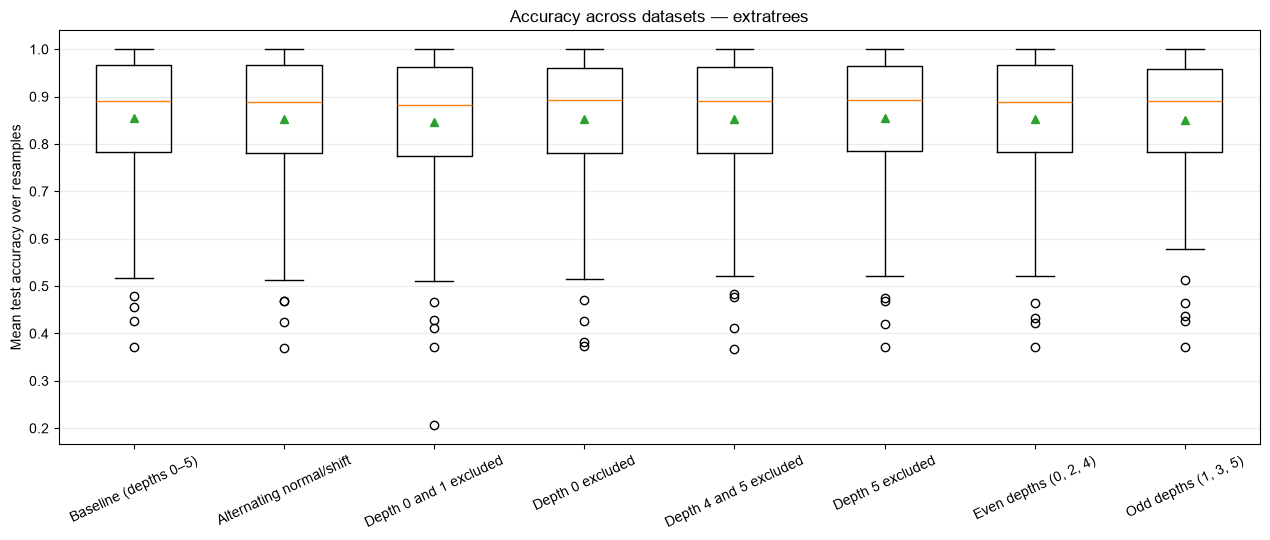

In [31]:
for clf in classifiers:
    data = table[table["classifier"] == clf]
    values = [data.loc[data["configuration"] == c, "accuracy"].dropna().to_numpy() for c in configs_in_order]
    fig, ax = plt.subplots(figsize=(max(8, 1.6 * len(configs_in_order)), 5.5))
    ax.boxplot(values, tick_labels=configs_in_order, showmeans=True)
    ax.set(ylabel="Mean test accuracy over resamples", title=f"Accuracy across datasets — {clf}")
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    plt.show()

## 8. Per-dataset changes versus the baseline, by group

One figure per metric and grouping (dataset size, then dataset type), one panel per group, datasets ordered from smallest to largest within each panel. The dashed line is "no change from baseline"; for every metric a bar **above** the line is better than the baseline.
The baseline is not drawn because it is zero by definition. Relative error reduction leaves an empty slot for datasets where the baseline is already perfect (undefined). Plain error difference is omitted since it is just the negative of the accuracy difference.

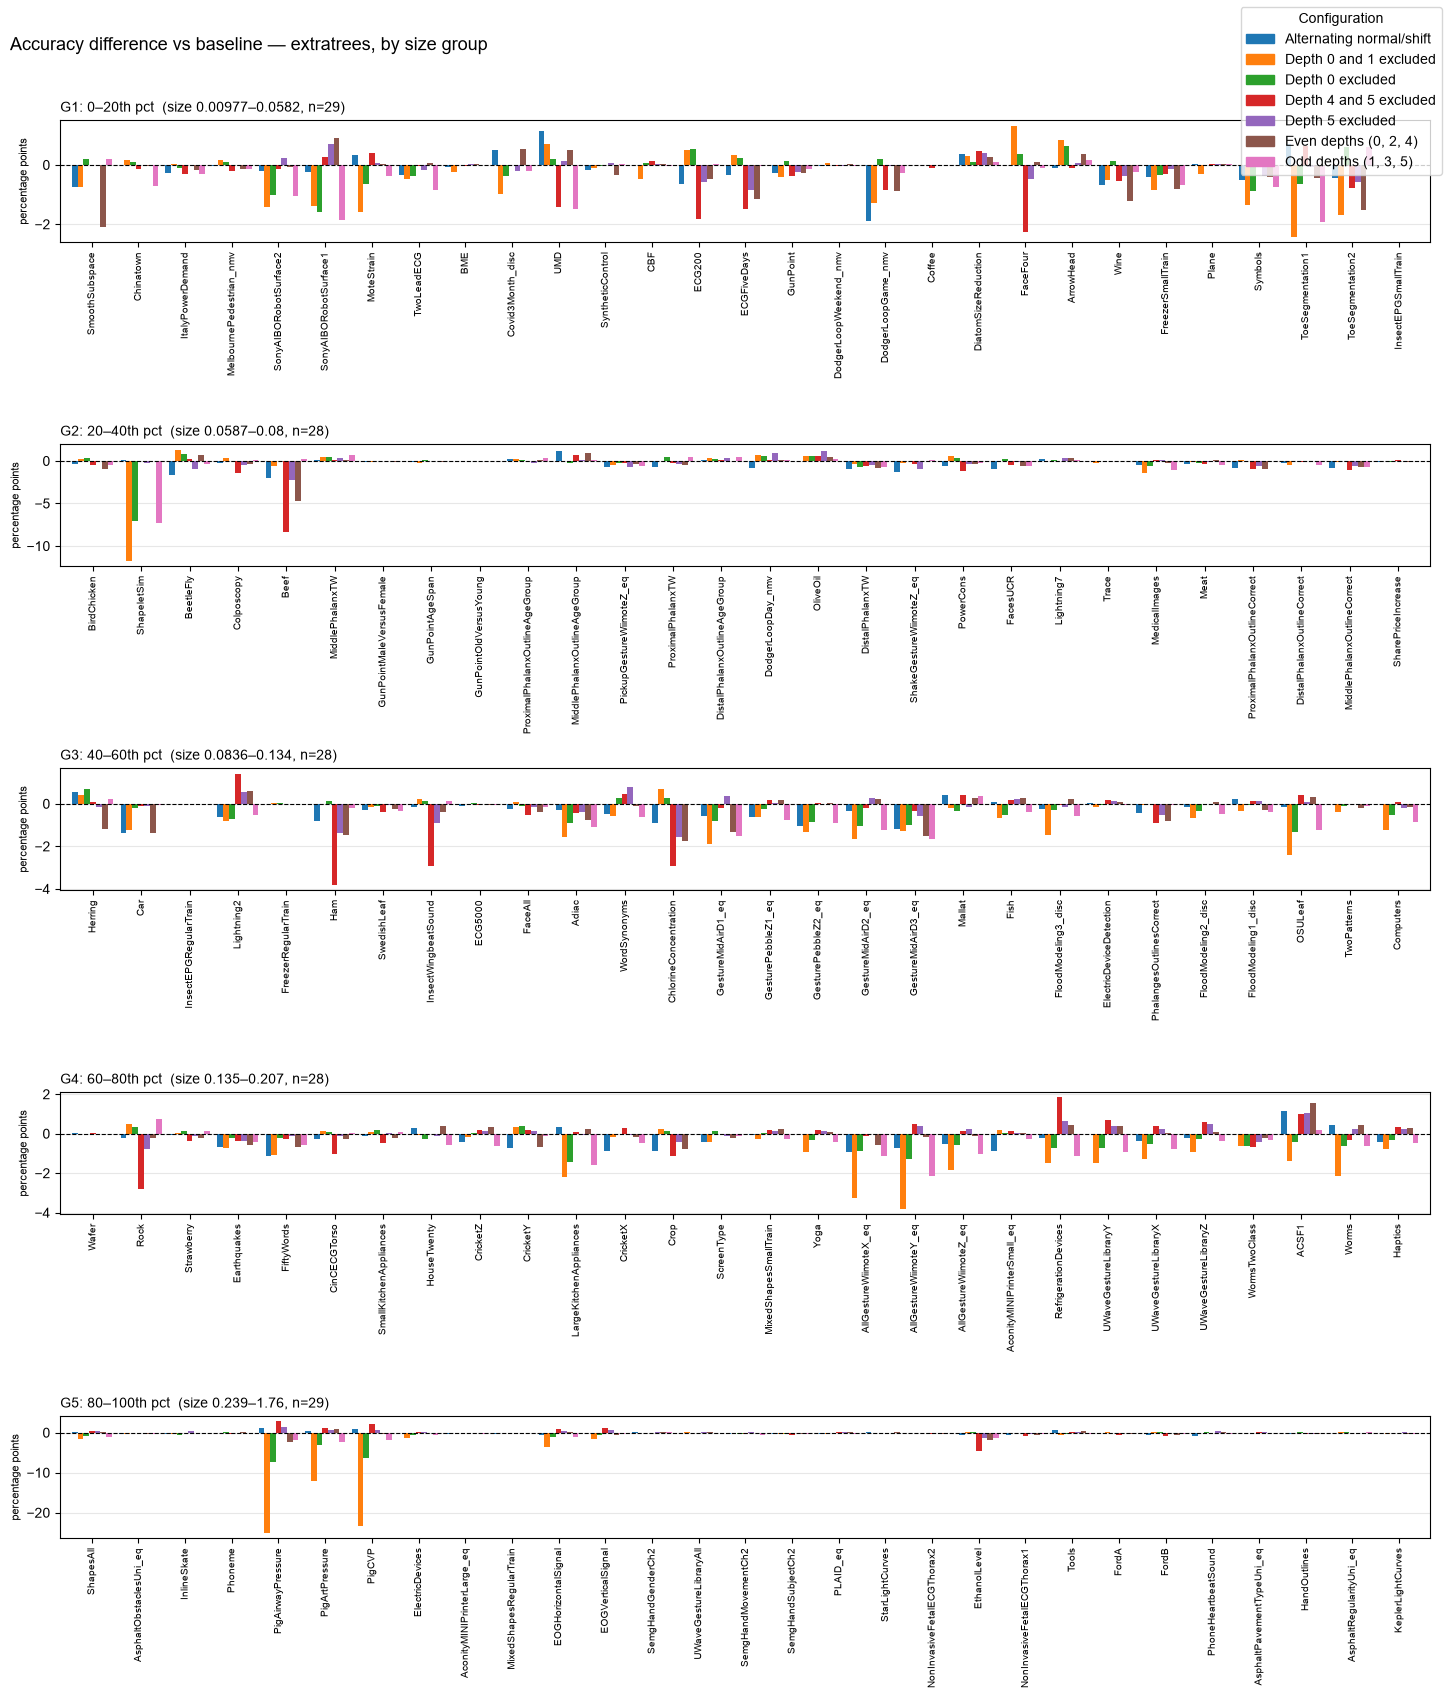

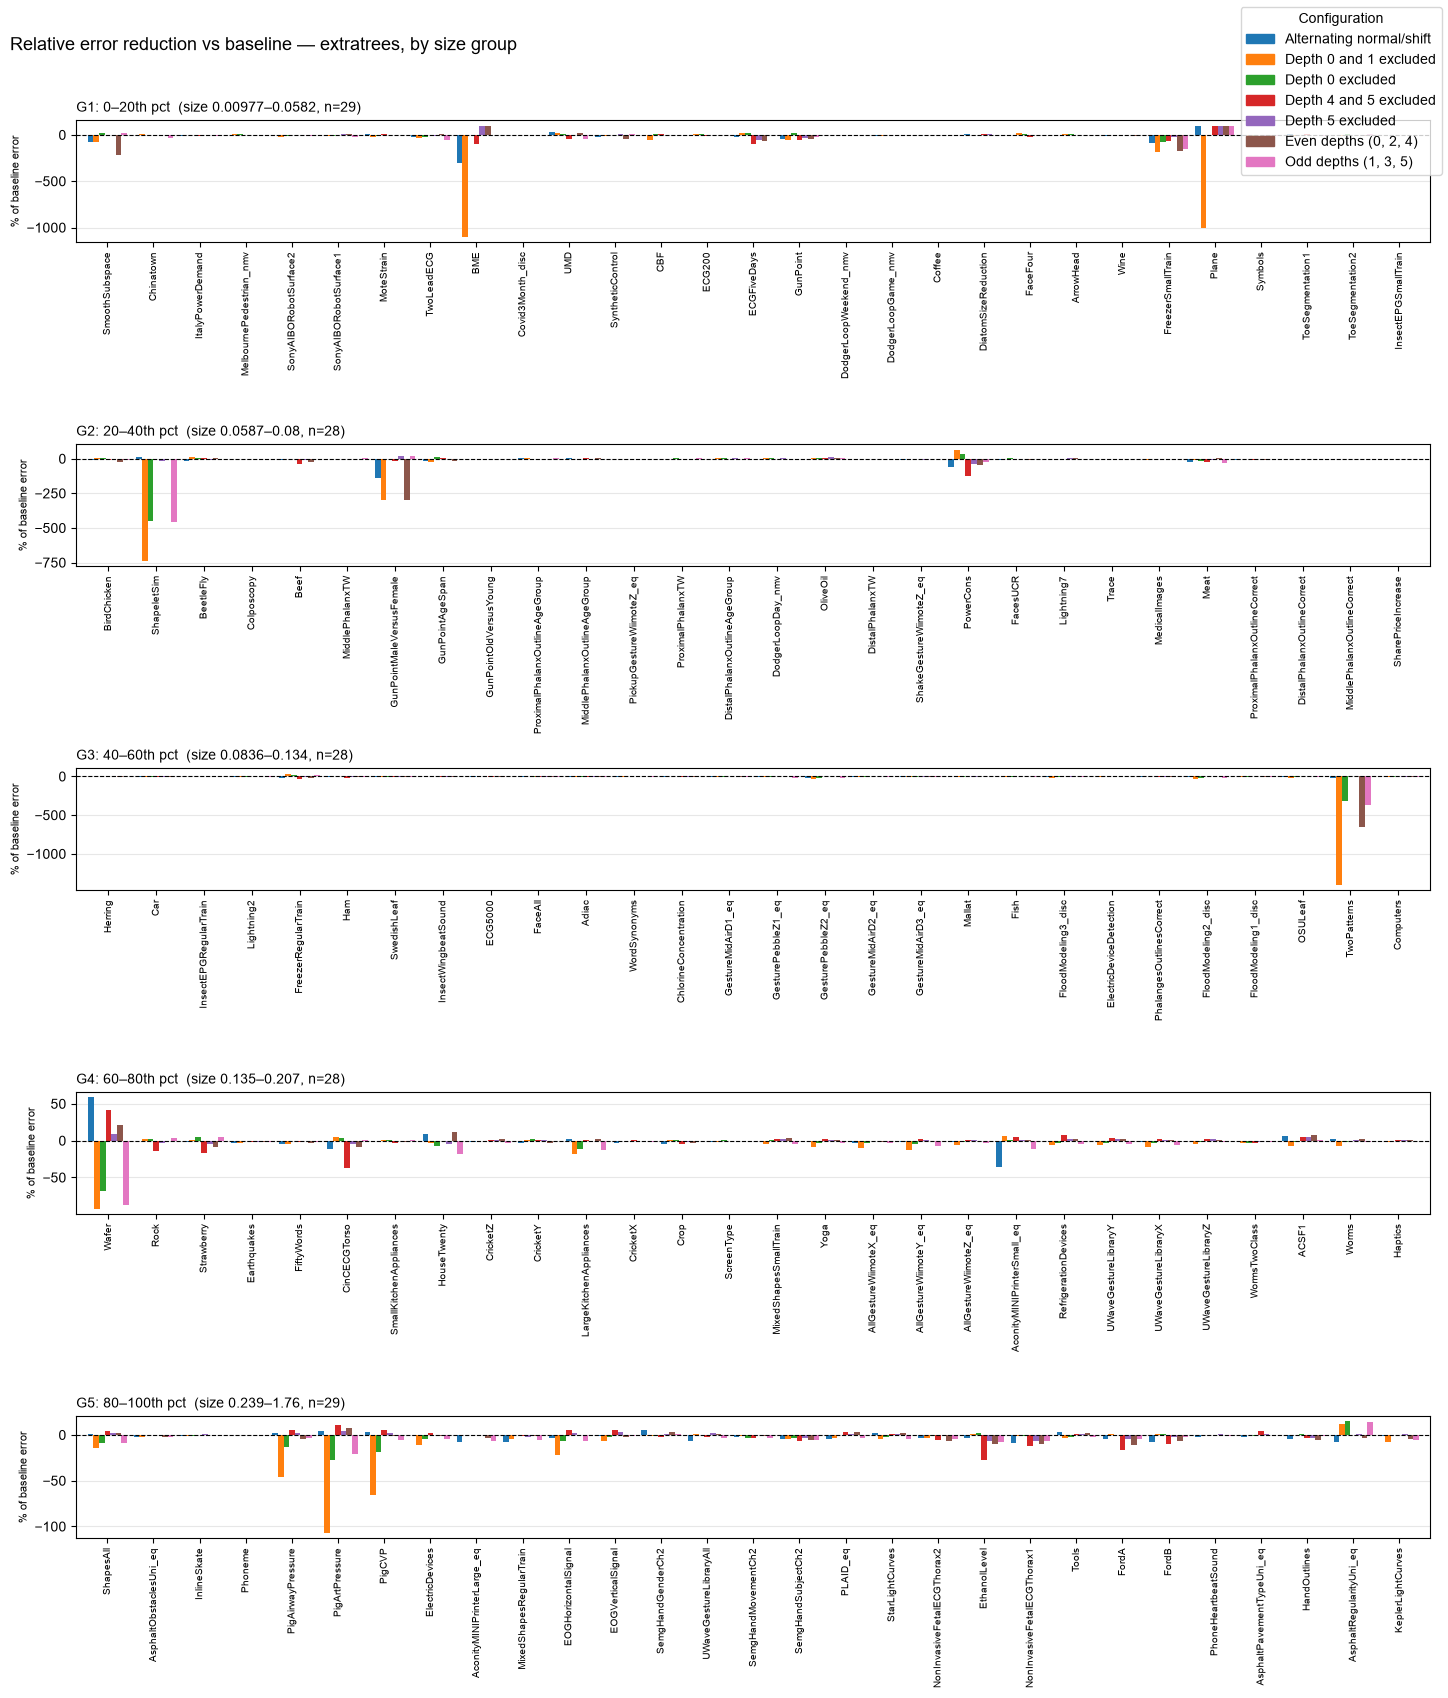

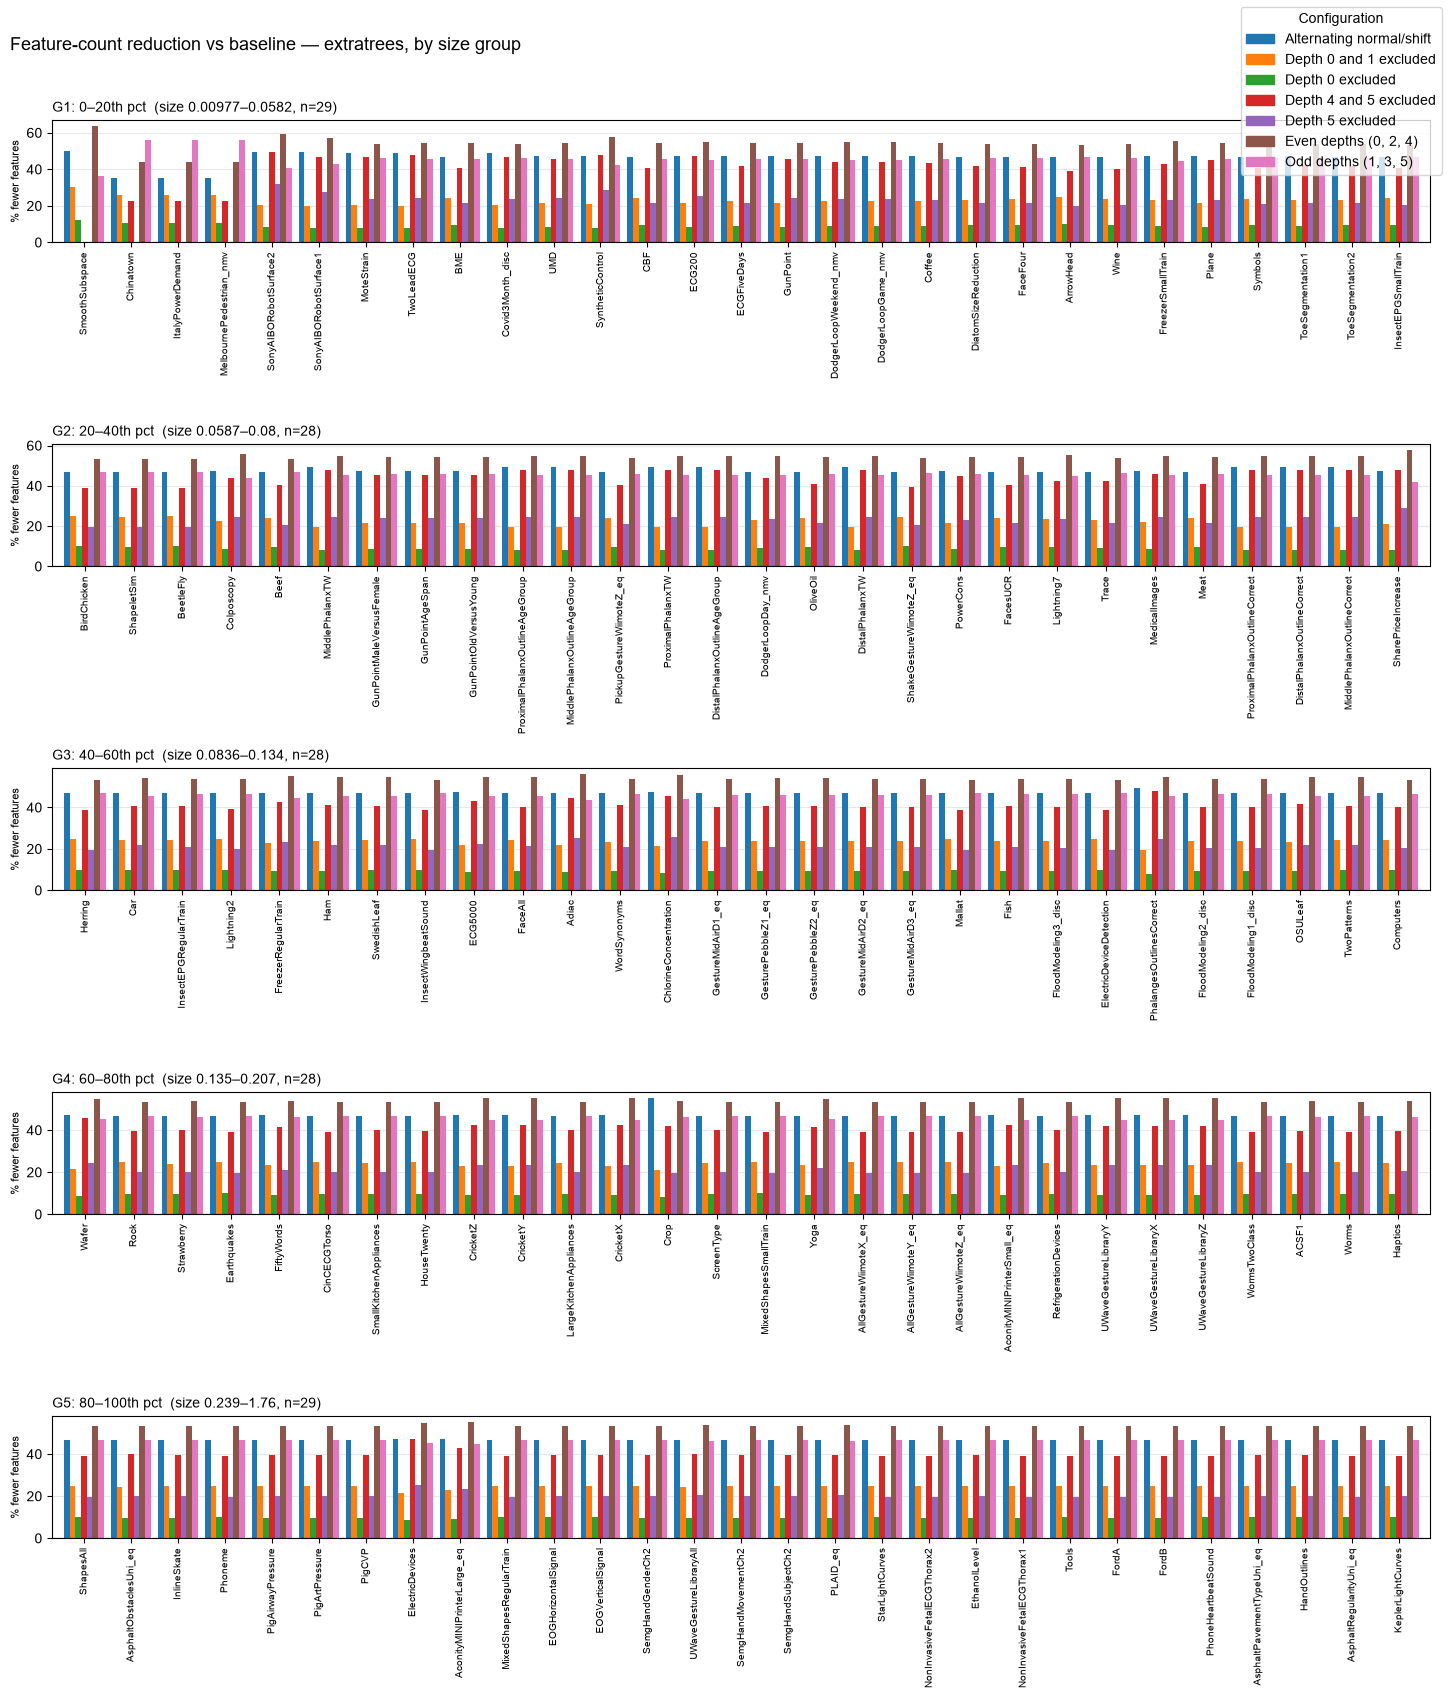

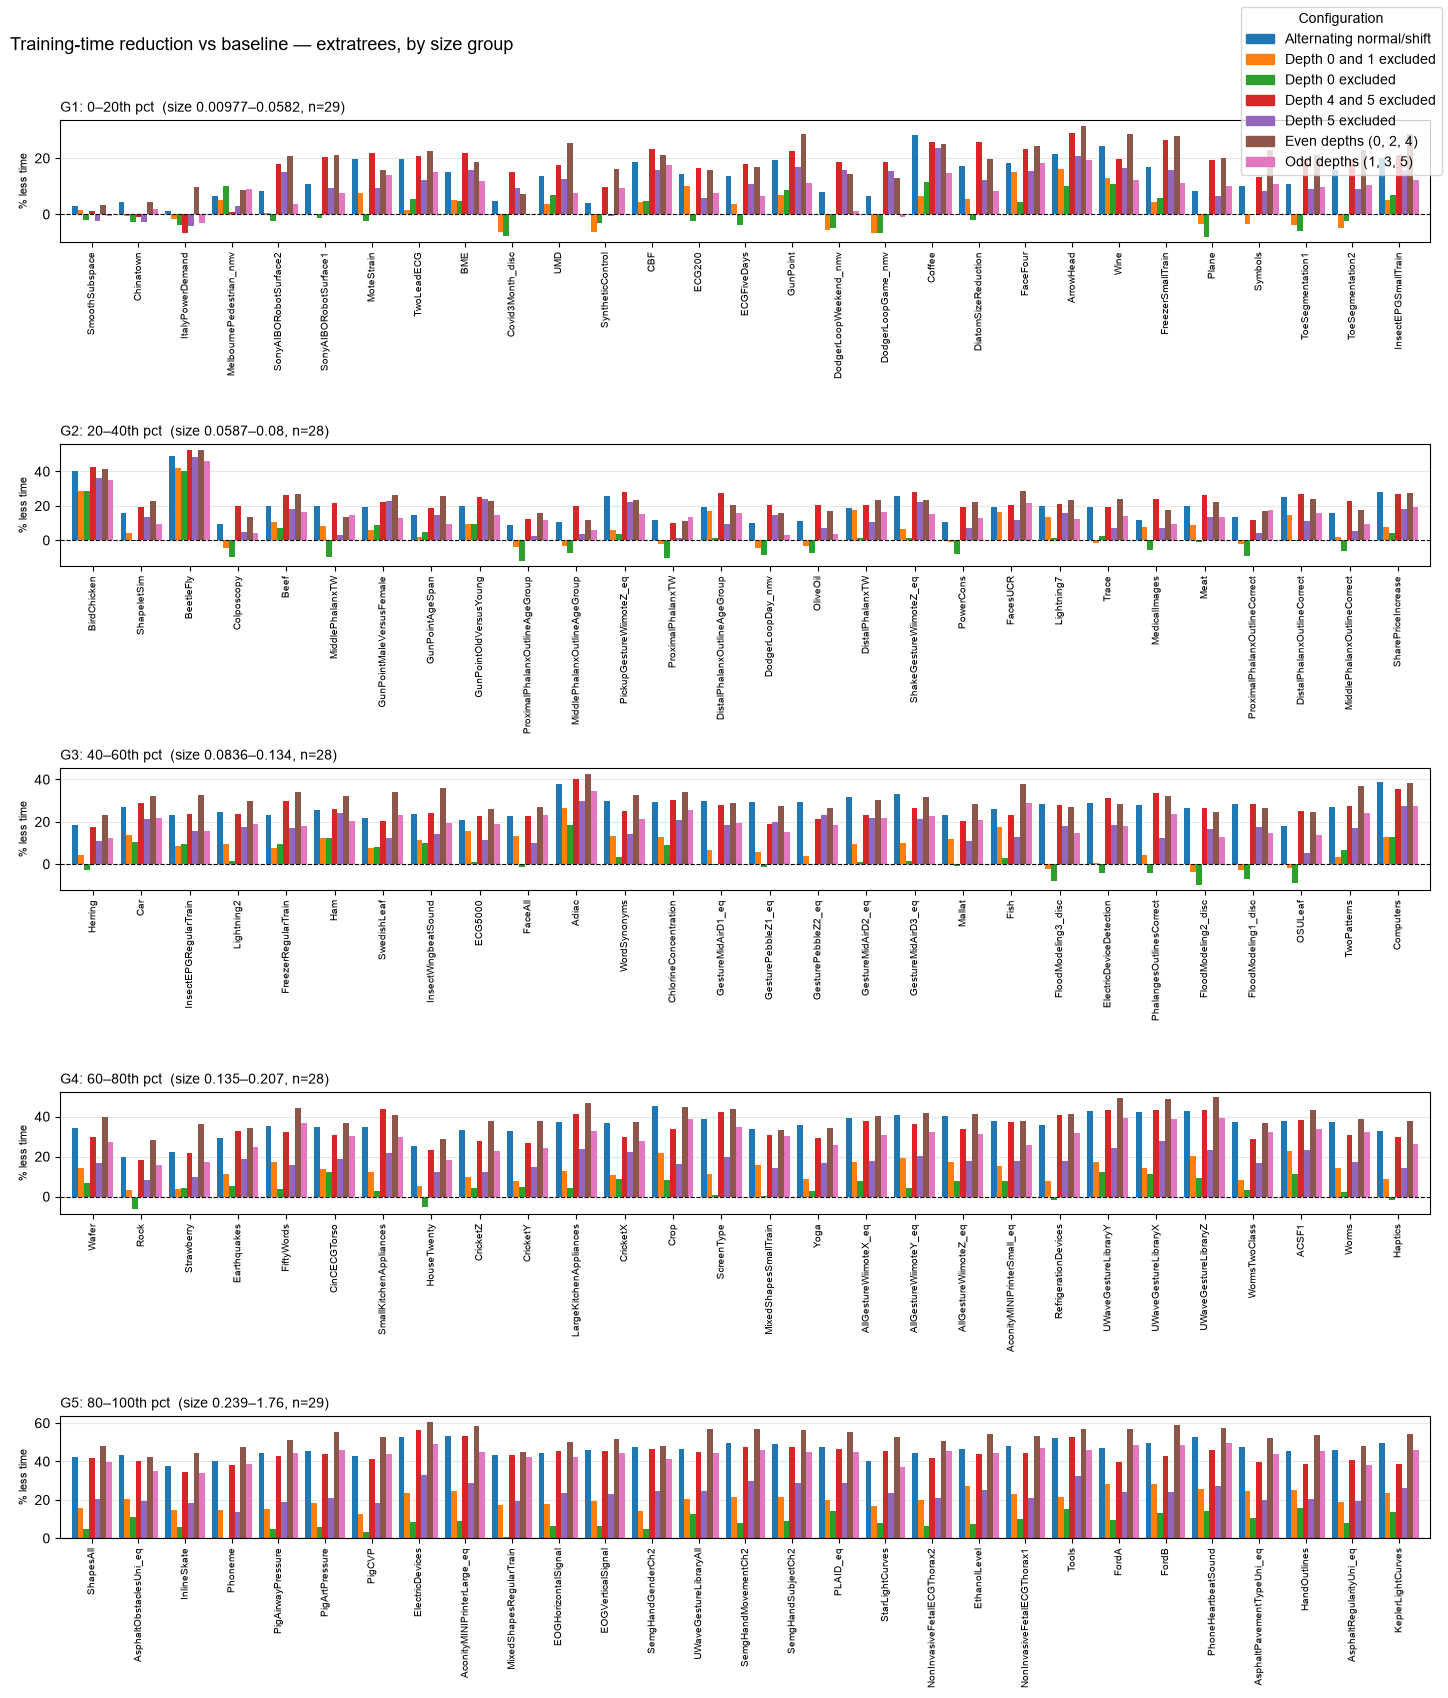

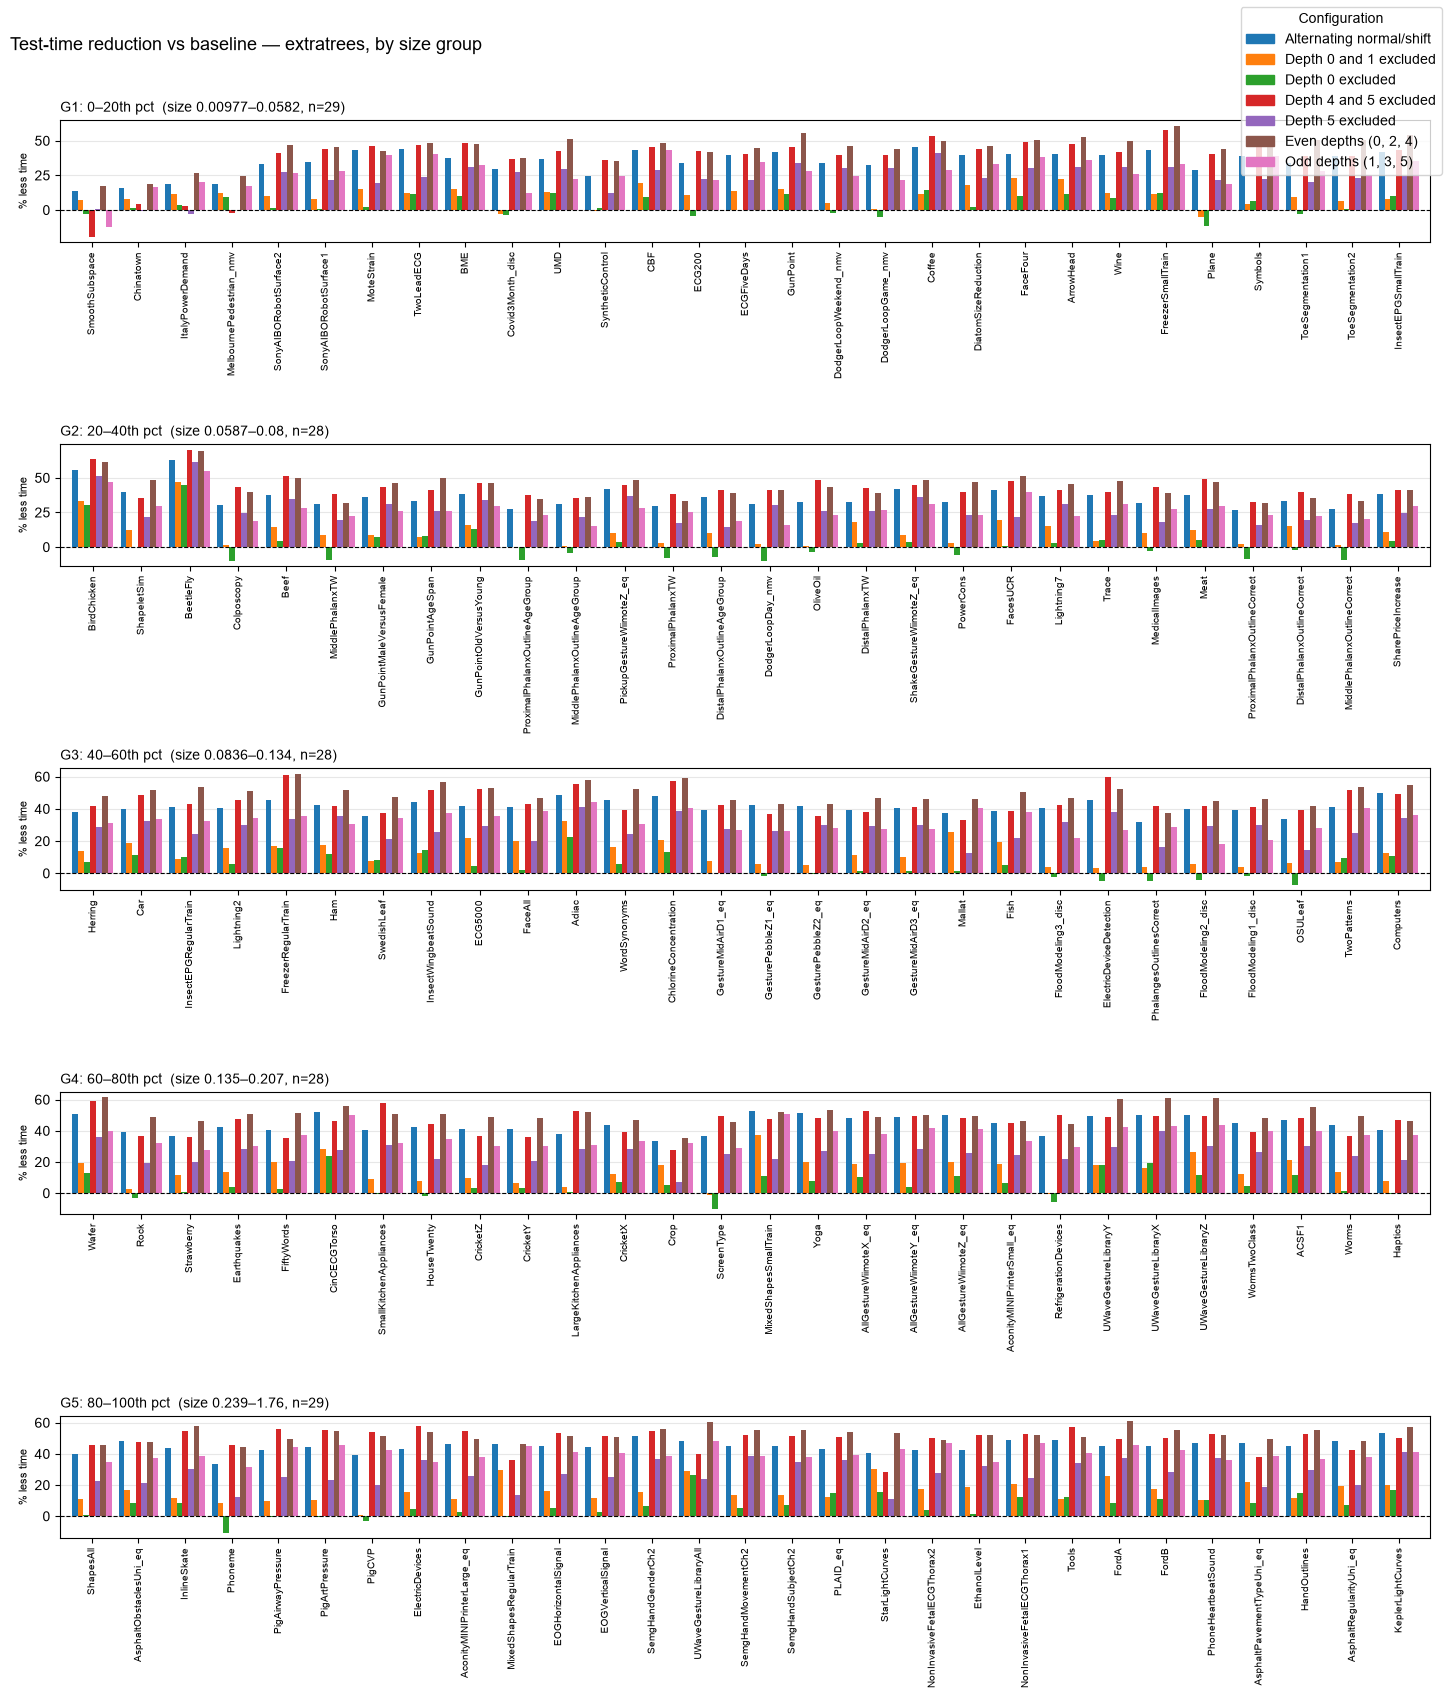

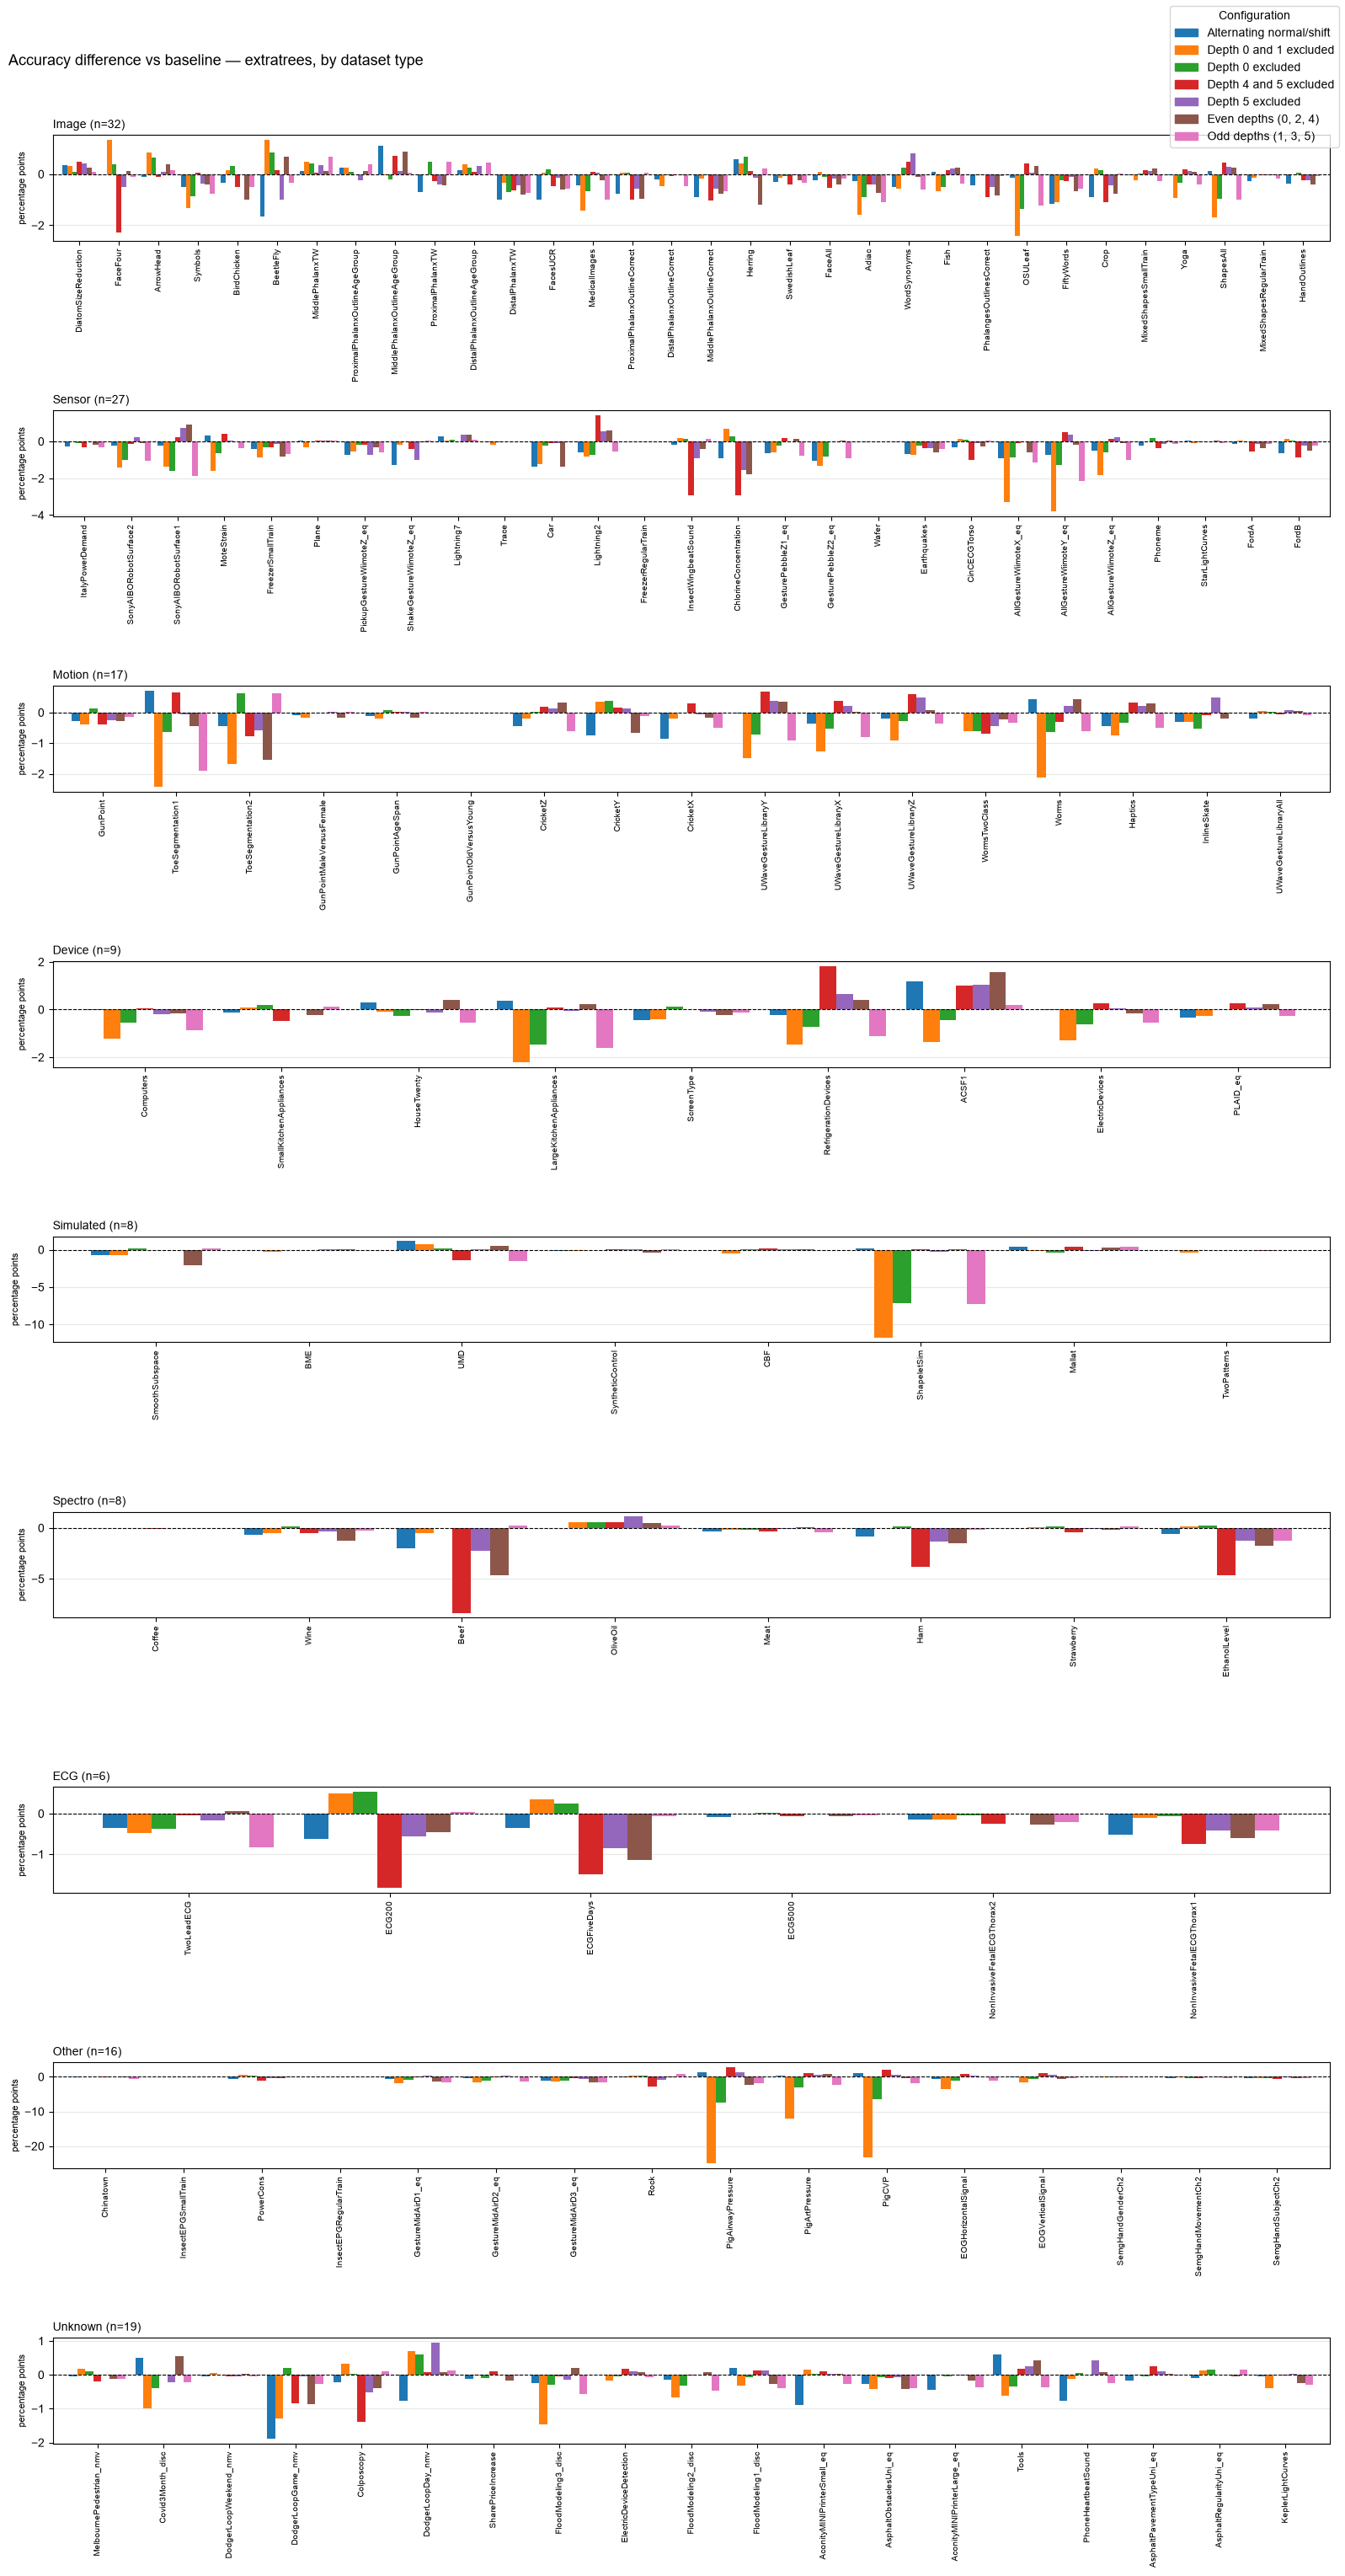

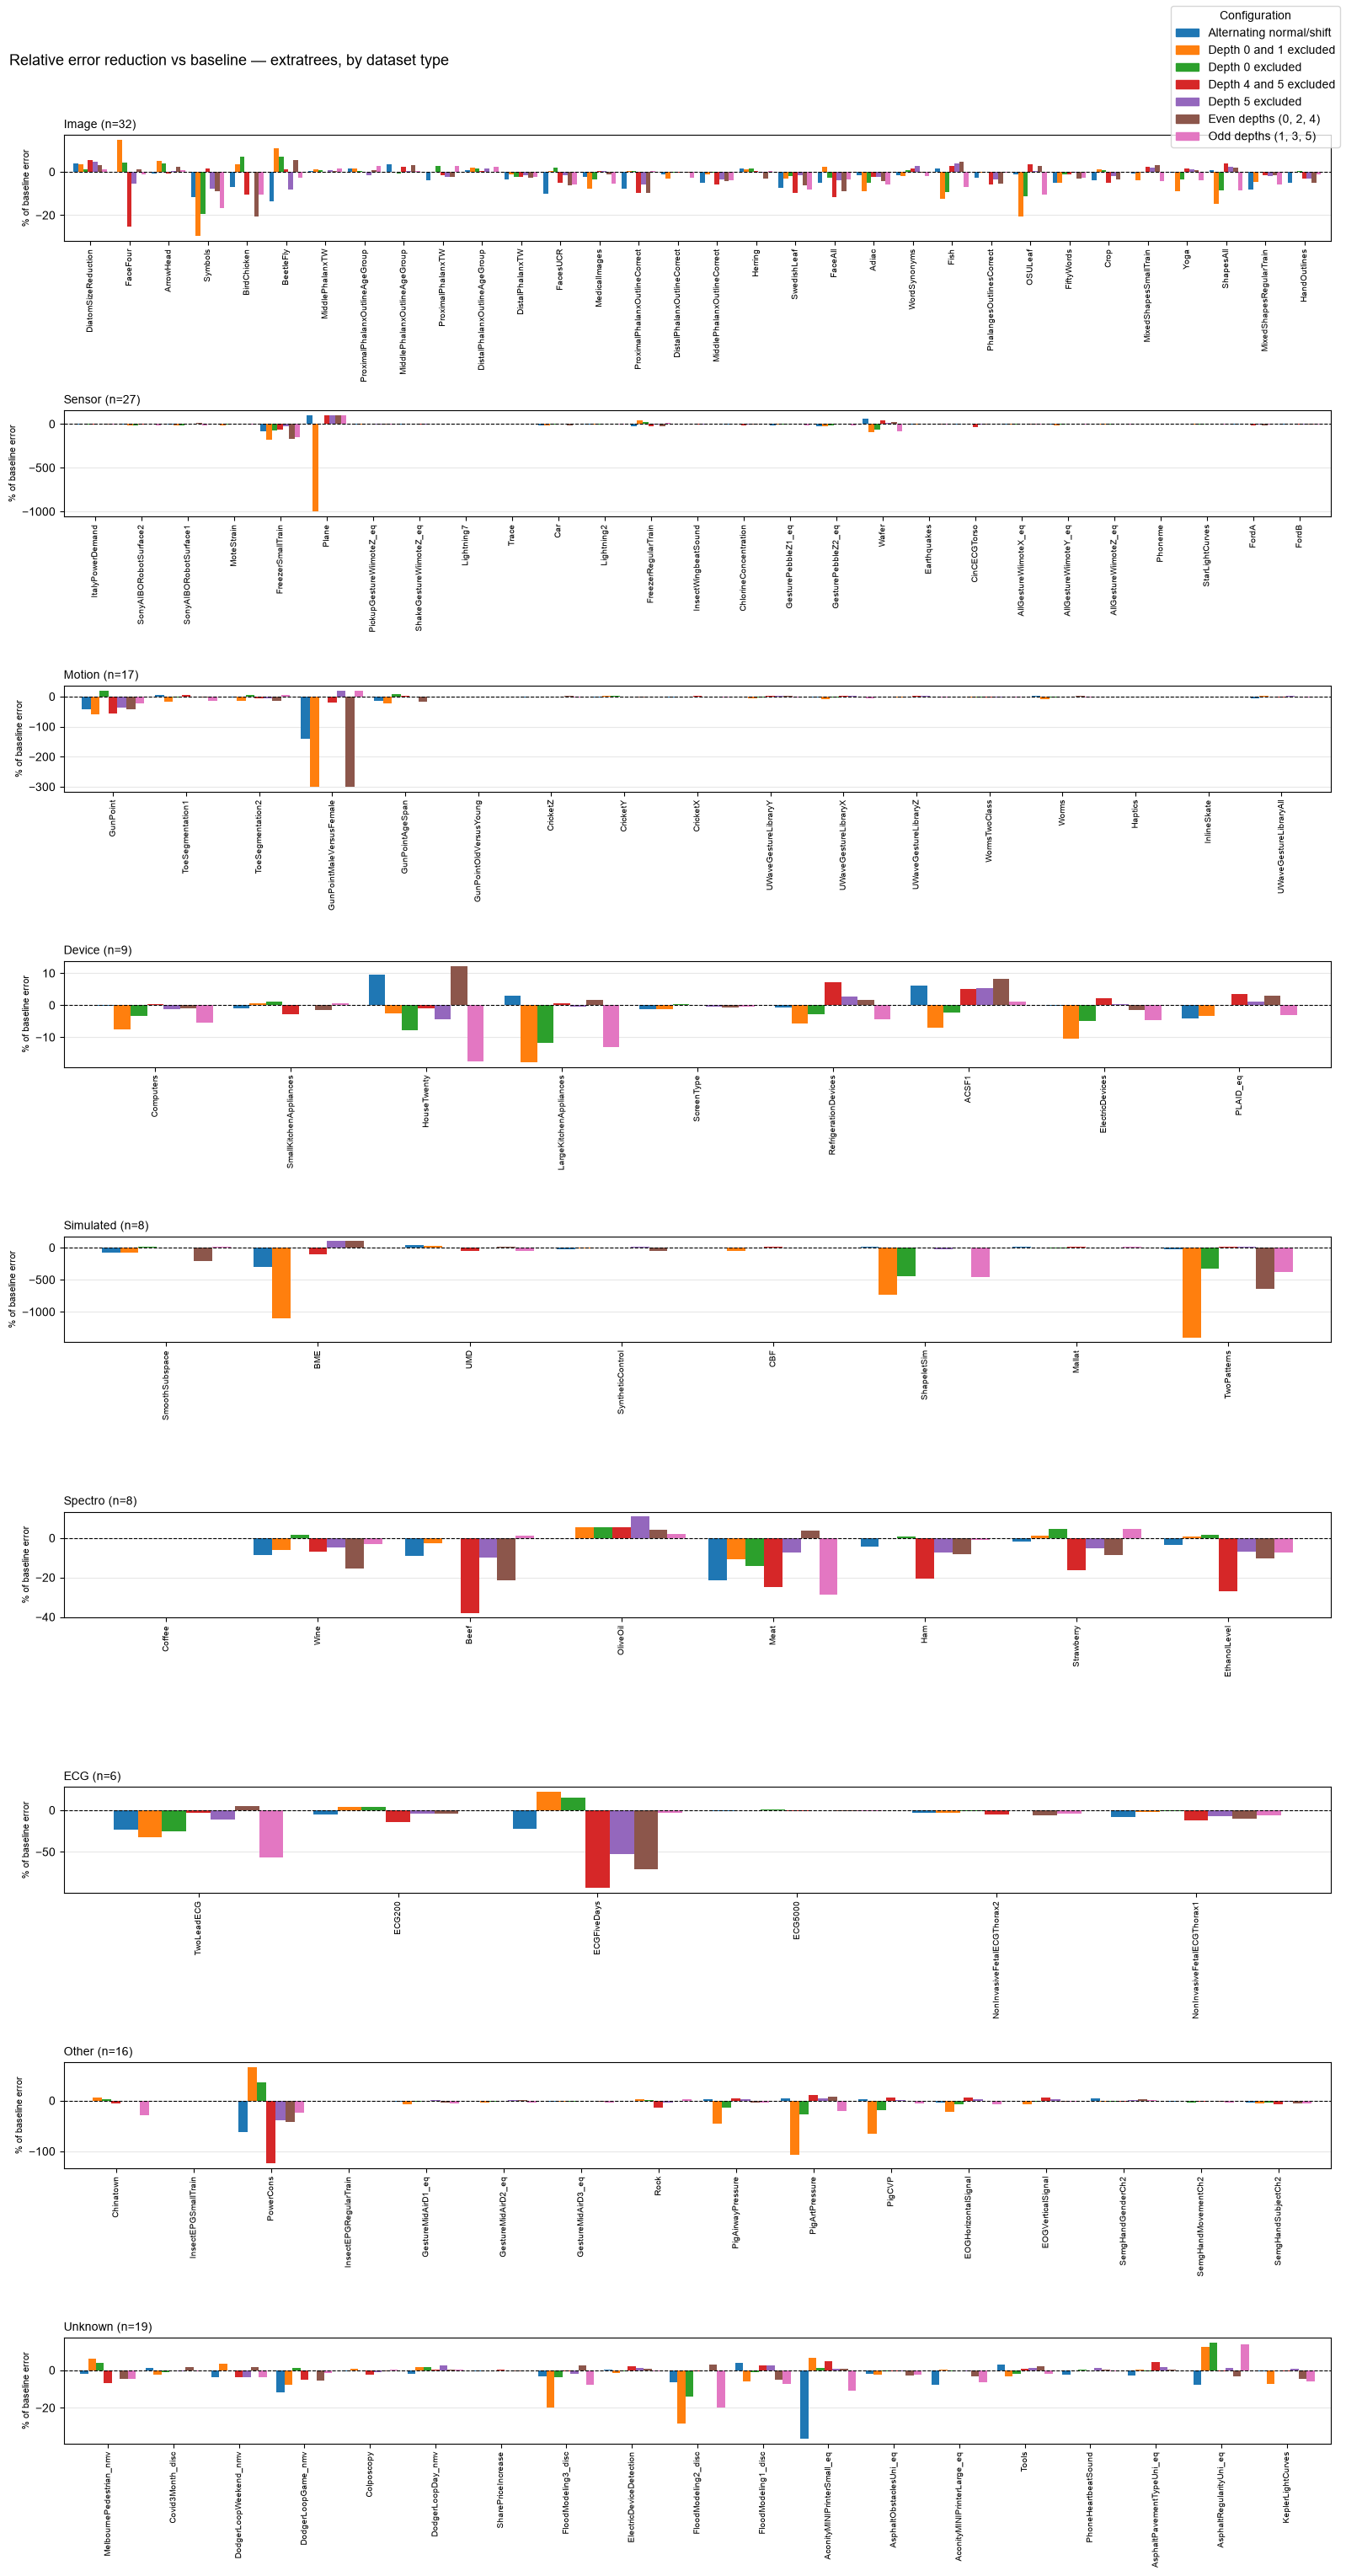

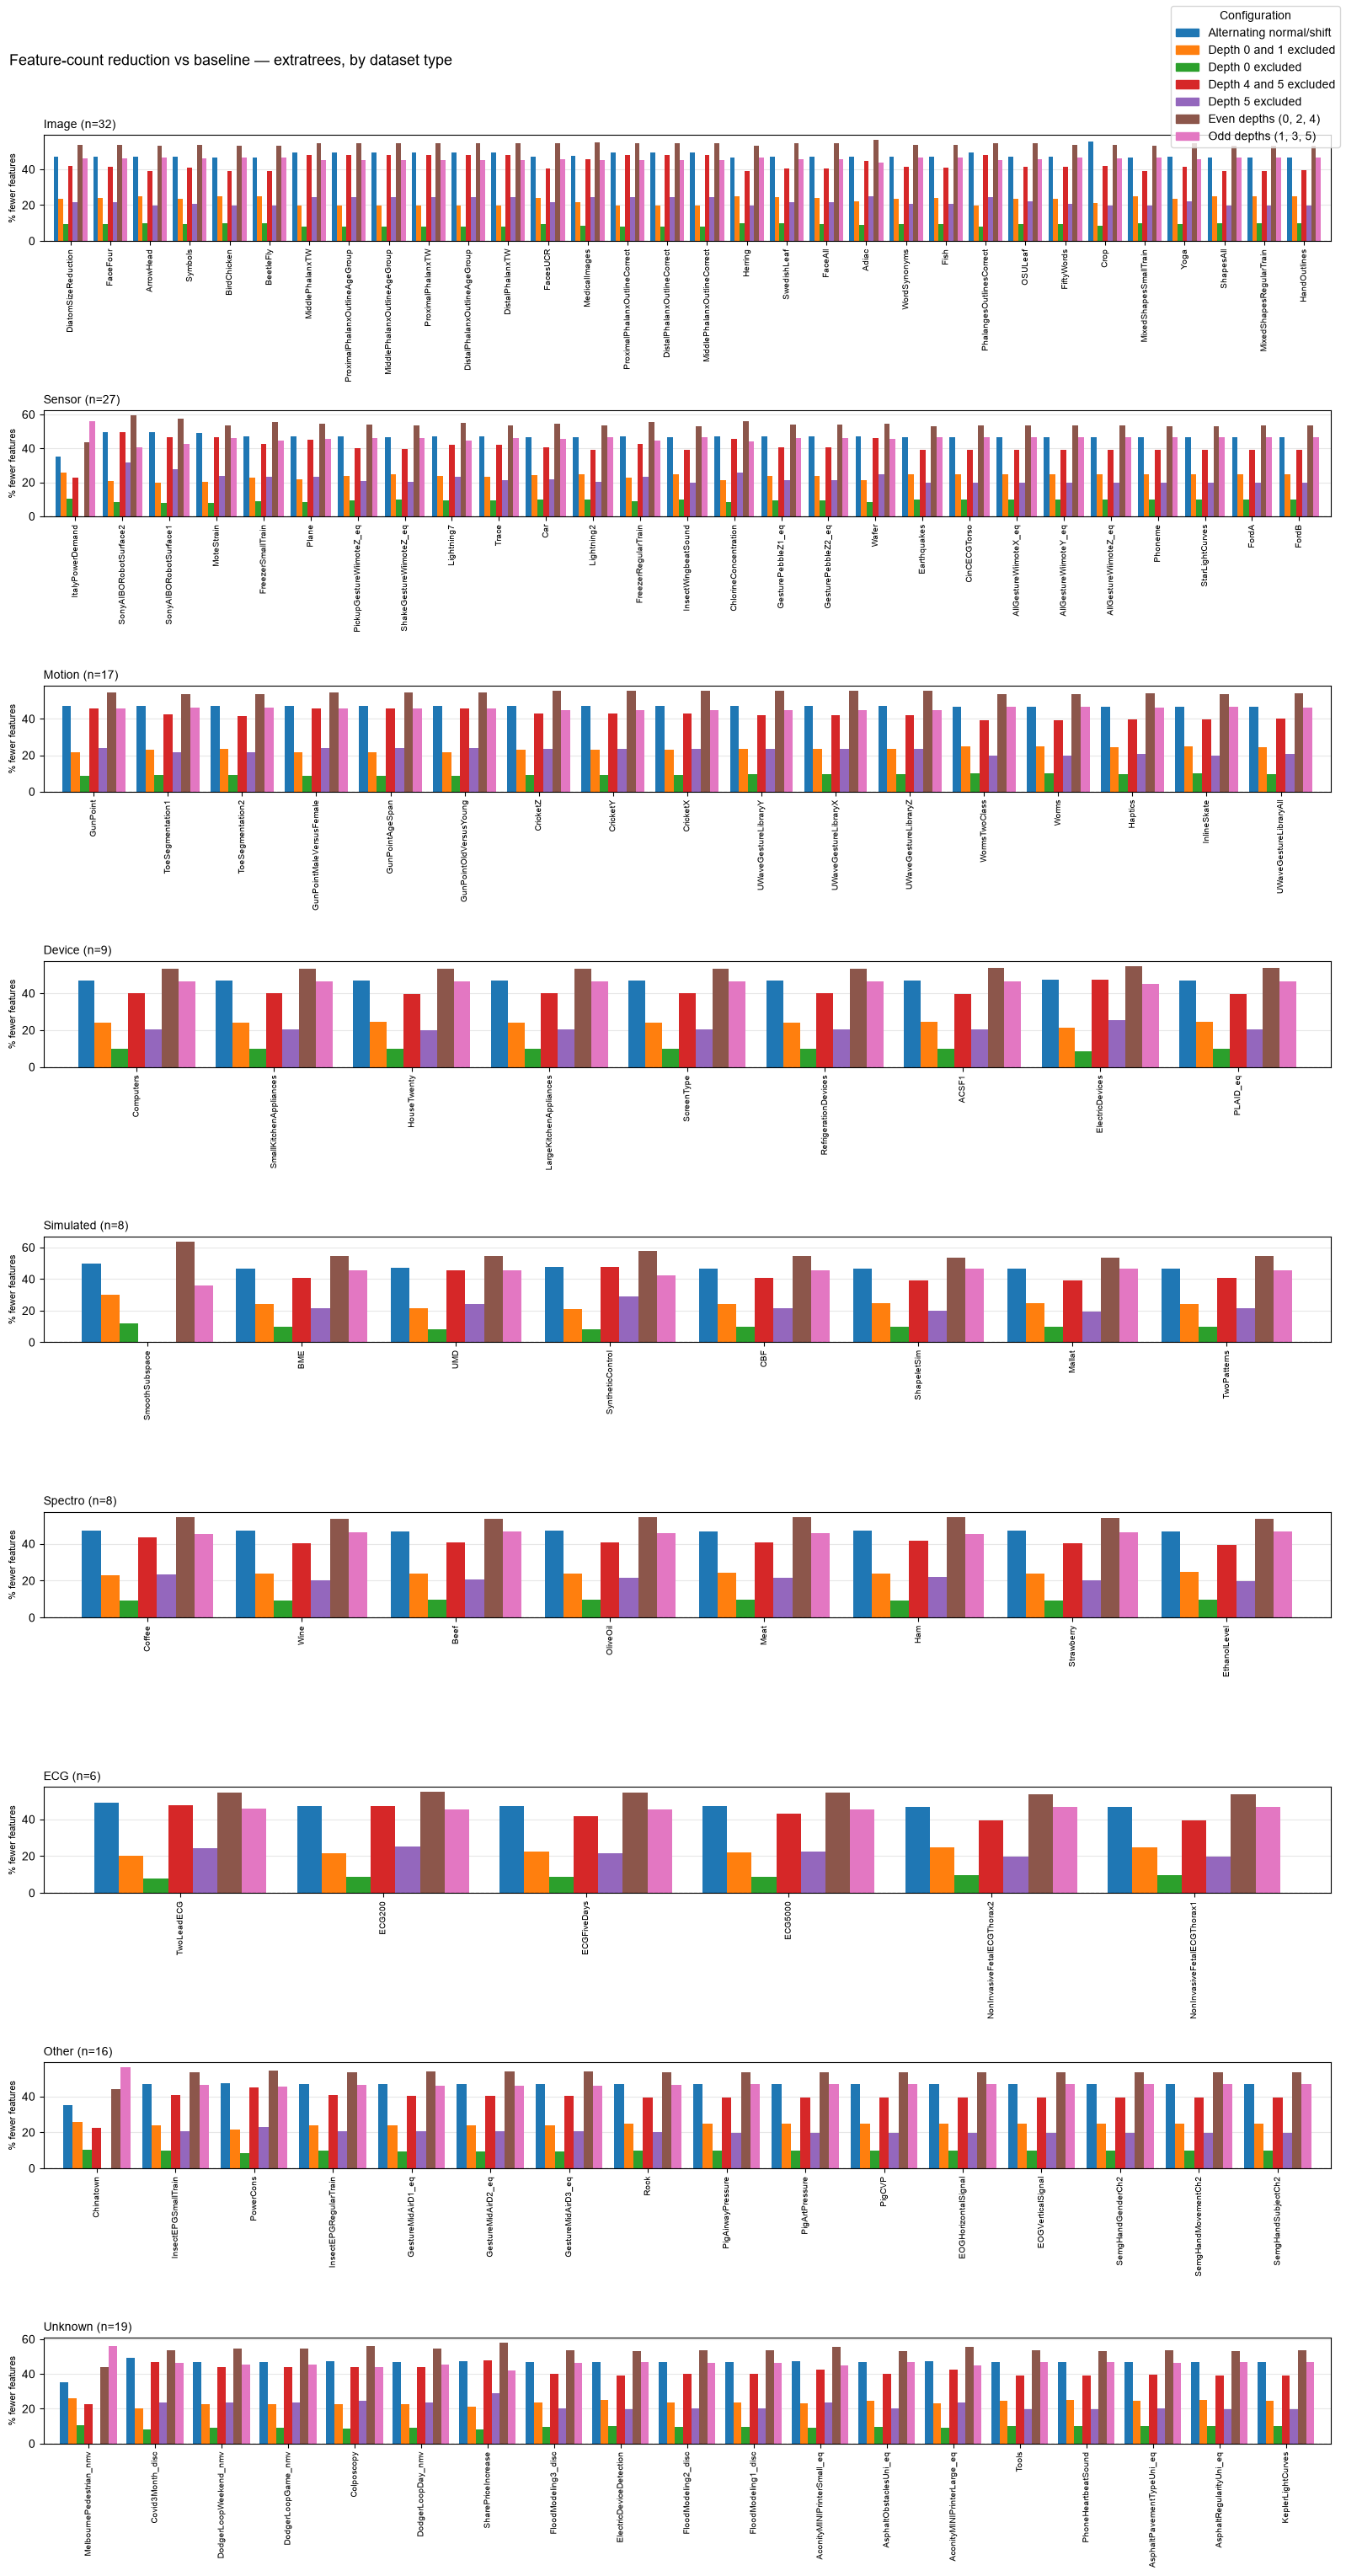

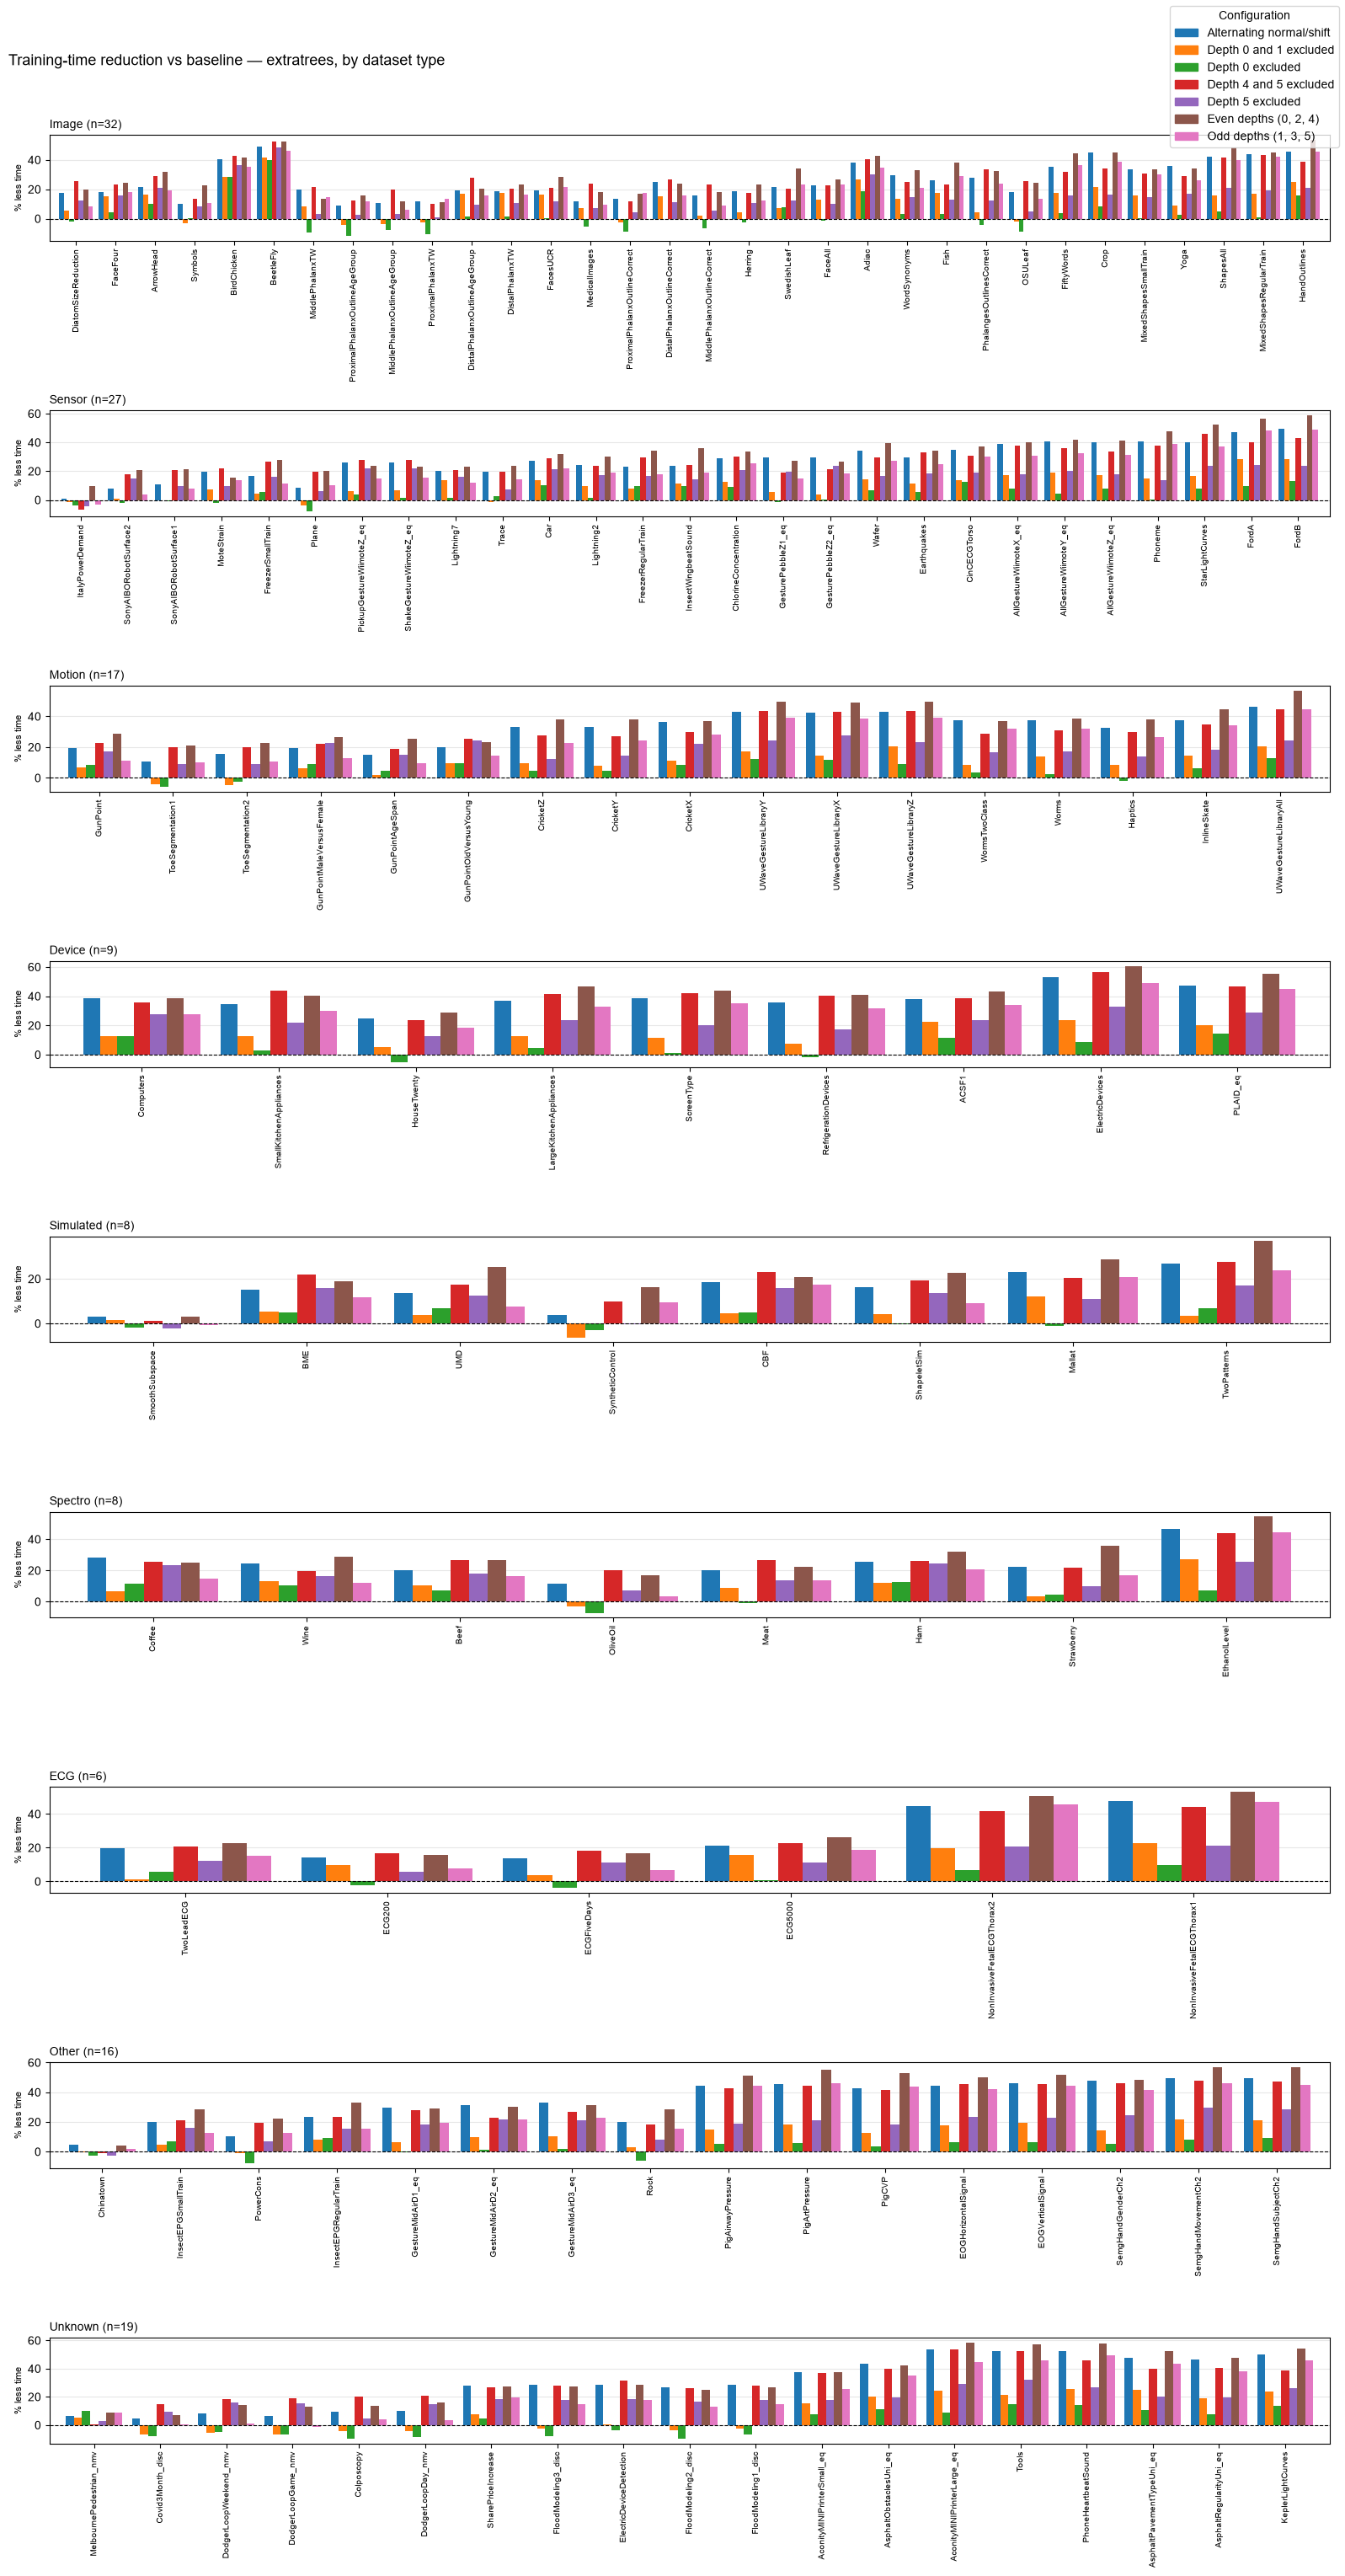

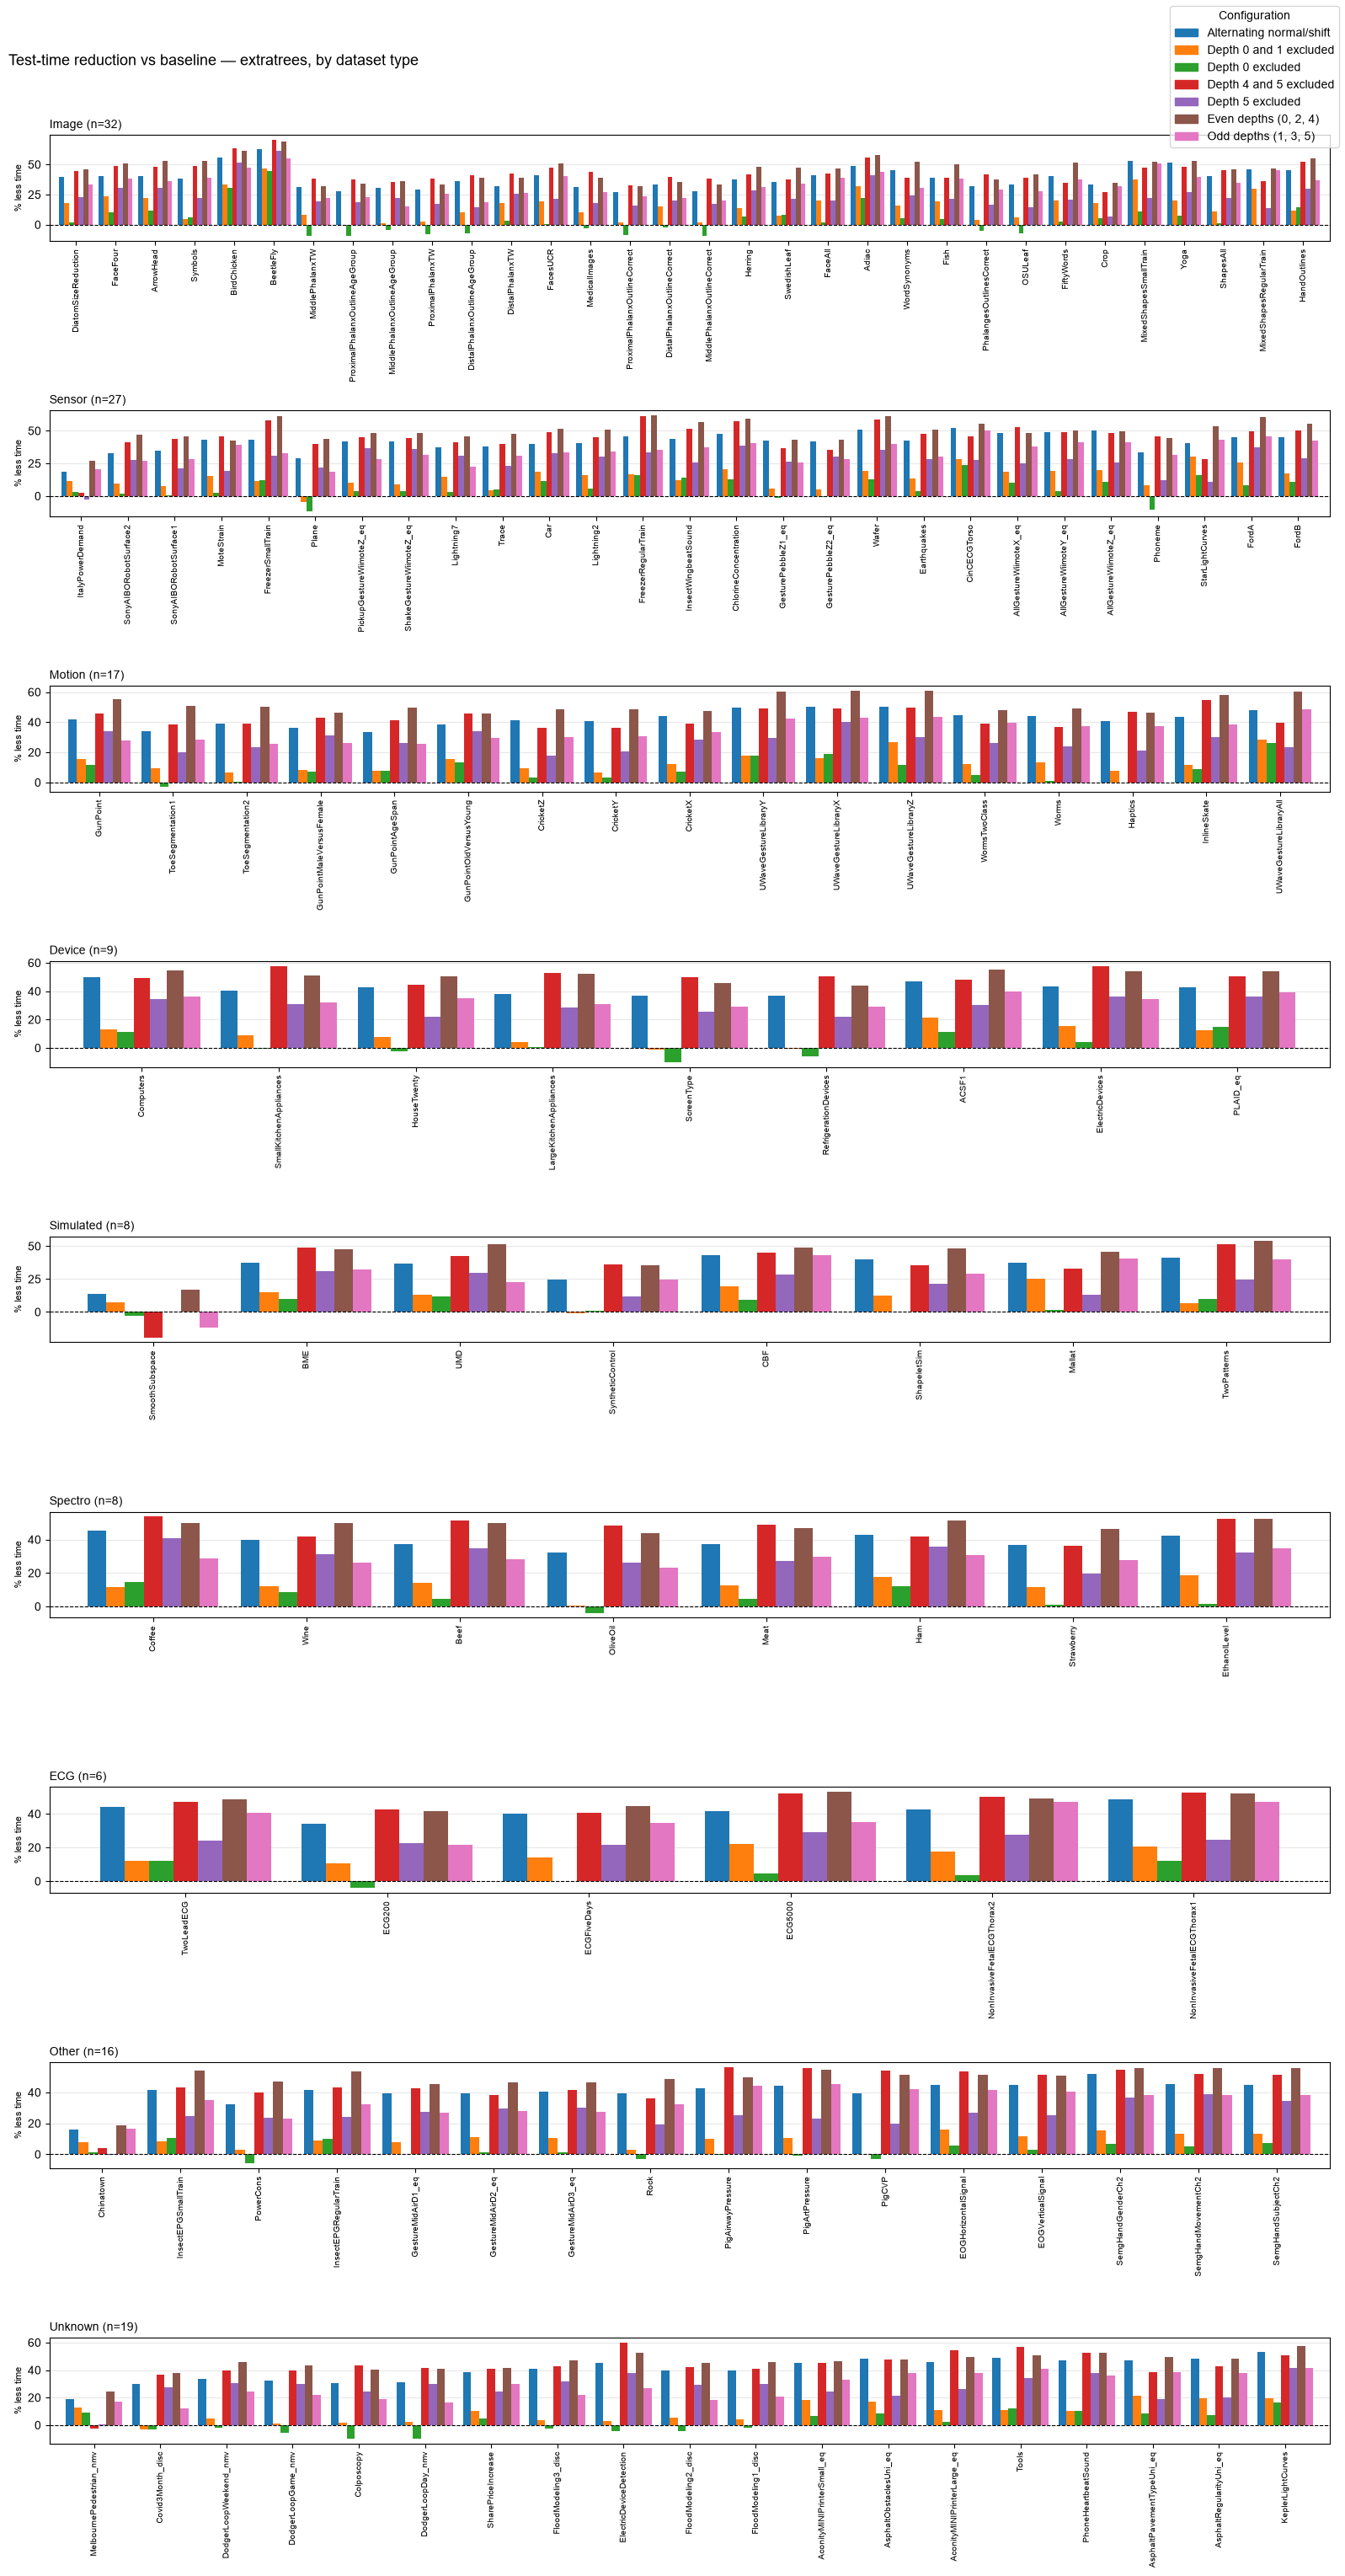

In [32]:
BAR_METRICS = {
    "acc_diff_pp": ("Accuracy difference vs baseline", "percentage points"),
    "error_reduction_pct": ("Relative error reduction vs baseline", "% of baseline error"),
    "feature_reduction_pct": ("Feature-count reduction vs baseline", "% fewer features"),
    "train_time_reduction_pct": ("Training-time reduction vs baseline", "% less time"),
    "test_time_reduction_pct": ("Test-time reduction vs baseline", "% less time"),
}

def plot_grouped_bars(metric, title, ylabel, grouping, col, order):
    for clf in classifiers:
        sub = cmp[cmp["classifier"] == clf]
        present = [name for name in order if (sub[col] == name).any()]
        if not present:
            continue
        widest = max((sub[col] == name).sum() // len(COMPARE_CONFIGS) for name in present)
        fig, axes = plt.subplots(len(present), 1, figsize=(max(14, 0.5 * widest), 3.4 * len(present)), squeeze=False)
        for ax, group_name in zip(axes[:, 0], present):
            g = sub[sub[col] == group_name]
            wide = g.pivot(index="dataset", columns="configuration", values=metric)
            wide = wide.loc[dataset_size.reindex(wide.index).sort_values().index, COMPARE_CONFIGS]
            wide.plot.bar(ax=ax, width=0.85, legend=False, color=[CONFIG_COLORS[c] for c in COMPARE_CONFIGS])
            ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
            ax.set_title(group_name, loc="left", fontsize=10)
            ax.set_xlabel("")
            ax.set_ylabel(ylabel, fontsize=8)
            ax.tick_params(axis="x", labelsize=7, rotation=90)
            ax.grid(axis="y", alpha=0.3)
            ax.set_axisbelow(True)
        fig.legend(handles=[Patch(color=CONFIG_COLORS[c], label=c) for c in COMPARE_CONFIGS],
                   title="Configuration", loc="upper right")
        fig.suptitle(f"{title} — {clf}, by {grouping}", x=0.01, ha="left", fontsize=13)
        fig.tight_layout(rect=(0, 0, 1, 0.97))
        plt.show()

for grouping, (col, order) in GROUPINGS.items():
    for metric, (title, ylabel) in BAR_METRICS.items():
        plot_grouped_bars(metric, title, ylabel, grouping, col, order)

## 9. Statistical significance

### 9a. Critical difference diagrams (across datasets)

Uses the Friedman test followed by Wilcoxon-Holm pairwise tests on the **per-dataset mean accuracies** (Demšar 2006; [hfawaz/cd-diagram](https://github.com/hfawaz/cd-diagram)). Methods joined by a thick bar are **not** significantly different. The first cell draws one diagram per classifier and per experiment group in `EXPERIMENT_GROUPS` (the baseline is always included); the second draws one per dataset-size group and one per dataset type.

Requires `cd_diagram.py`: the repo's `main.py`, renamed and with four small patches (no forced `agg` backend, no `exit()`, an output-file argument, and the example code guarded by `if __name__ == "__main__"`). The Friedman test needs at least 3 methods in a diagram, i.e. the baseline plus at least 2 configurations.

A significant rank difference means the configuration is *consistently* better or worse across datasets, not that the difference is large. Read it together with the accuracy differences in section 6. Groups contain only a few dozen datasets (or fewer), so "no significant difference" in a group mostly means low power, not evidence of equivalence.

<StringArray>
['Alternating normal/shift', 'Baseline (depths 0–5)', 'Depth 0 and 1 excluded', 'Depth 0 excluded', 'Depth 4 and 5 excluded', 'Depth 5 excluded', 'Even depths (0, 2, 4)', 'Odd depths (1, 3, 5)']
Length: 8, dtype: str
Alternating normal/shift    11.0
Baseline (depths 0–5)       14.0
Depth 0 and 1 excluded      21.0
Depth 0 excluded            18.0
Depth 4 and 5 excluded      29.0
Depth 5 excluded            16.0
Even depths (0, 2, 4)       12.0
Odd depths (1, 3, 5)        11.0
dtype: float64
Odd depths (1, 3, 5)        5.295775
Depth 0 and 1 excluded      5.253521
Alternating normal/shift    5.197183
Even depths (0, 2, 4)       4.588028
Depth 4 and 5 excluded      4.387324
Depth 0 excluded            4.133803
Baseline (depths 0–5)       3.573944
Depth 5 excluded            3.570423
dtype: float64
('Baseline (depths 0–5)', 'Odd depths (1, 3, 5)', np.float64(5.793560046286557e-13), True)
('Depth 0 and 1 excluded', 'Depth 0 excluded', np.float64(3.286445398081082e-10), True)


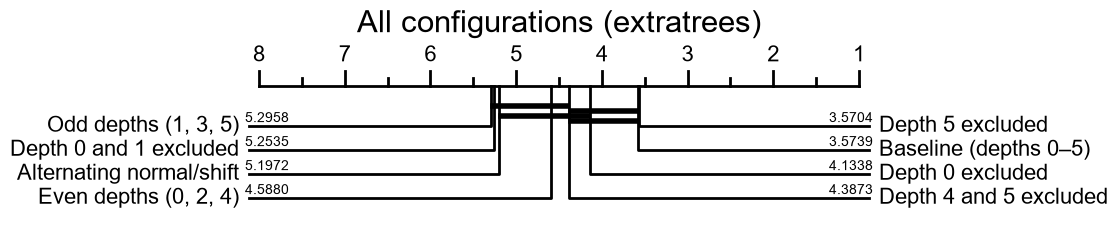

In [33]:
import re
import sys

CD_DIAGRAM_DIR = Path("..")      # folder that contains cd_diagram.py
sys.path.insert(0, str(CD_DIAGRAM_DIR.resolve()))
from cd_diagram import draw_cd_diagram

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
CD_ALPHA = 0.05

# One diagram per group below (the baseline is added to every group automatically).
EXPERIMENT_GROUPS = {
    "All configurations": COMPARE_CONFIGS,
    # "Depth removal": ["Depth 6 excluded", "Depth 5 and 6 excluded"],
    # "Interval selection": ["Even depths (0, 2, 4, 6)", "Alternating normal/shift"],
}

for clf in classifiers:
    for group_name, group_configs in EXPERIMENT_GROUPS.items():
        names = [BASELINE] + [c for c in group_configs if c != BASELINE]
        if len(names) < 3:
            print(f"Skipping '{group_name}' ({clf}): the Friedman test needs at least 3 methods, got {len(names)}.")
            continue
        slug = re.sub(r"\W+", "_", group_name)
        df_perf = (
            table[(table["classifier"] == clf) & table["configuration"].isin(names)]
            .rename(columns={"configuration": "classifier_name", "dataset": "dataset_name"})
            [["classifier_name", "dataset_name", "accuracy"]]
        )
        try:
            draw_cd_diagram(
                df_perf=df_perf, alpha=CD_ALPHA, title=f"{group_name} ({clf})", labels=True,
                filename=FIG_DIR / f"cd_{clf}_{slug}.png",
            )
        except RuntimeError as err:          # Friedman test not significant
            print(f"No diagram for '{group_name}' ({clf}): {err}")

<StringArray>
['Alternating normal/shift', 'Baseline (depths 0–5)', 'Depth 0 and 1 excluded', 'Depth 0 excluded', 'Depth 4 and 5 excluded', 'Depth 5 excluded', 'Even depths (0, 2, 4)', 'Odd depths (1, 3, 5)']
Length: 8, dtype: str
Alternating normal/shift    2.0
Baseline (depths 0–5)       1.0
Depth 0 and 1 excluded      7.0
Depth 0 excluded            4.0
Depth 4 and 5 excluded      4.0
Depth 5 excluded            2.0
Even depths (0, 2, 4)       3.0
Odd depths (1, 3, 5)        2.0
dtype: float64
Odd depths (1, 3, 5)        5.258621
Depth 0 and 1 excluded      5.120690
Depth 4 and 5 excluded      4.948276
Alternating normal/shift    4.896552
Even depths (0, 2, 4)       4.500000
Depth 0 excluded            3.879310
Depth 5 excluded            3.706897
Baseline (depths 0–5)       3.689655
dtype: float64
('Depth 0 excluded', 'Odd depths (1, 3, 5)', np.float64(0.0021972424214215616), False)
('Baseline (depths 0–5)', 'Odd depths (1, 3, 5)', np.float64(0.002923912859057575), False)
('Baselin

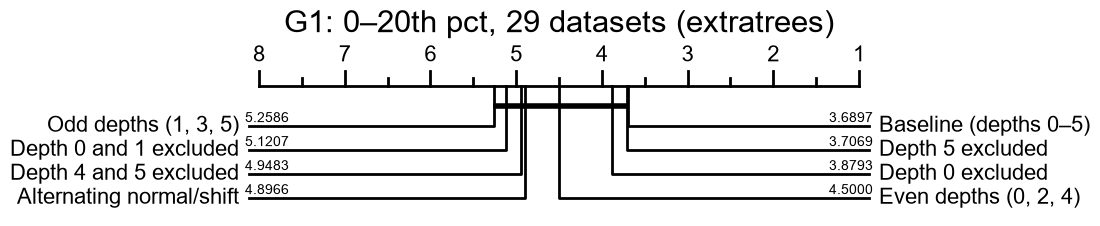

<StringArray>
['Alternating normal/shift', 'Baseline (depths 0–5)', 'Depth 0 and 1 excluded', 'Depth 0 excluded', 'Depth 4 and 5 excluded', 'Depth 5 excluded', 'Even depths (0, 2, 4)', 'Odd depths (1, 3, 5)']
Length: 8, dtype: str
Alternating normal/shift    2.0
Baseline (depths 0–5)       3.0
Depth 0 and 1 excluded      4.0
Depth 0 excluded            3.0
Depth 4 and 5 excluded      2.0
Depth 5 excluded            3.0
Even depths (0, 2, 4)       1.0
Odd depths (1, 3, 5)        7.0
dtype: float64
Alternating normal/shift    5.857143
Even depths (0, 2, 4)       5.125000
Depth 4 and 5 excluded      5.053571
Depth 0 and 1 excluded      4.125000
Baseline (depths 0–5)       4.107143
Depth 5 excluded            4.071429
Odd depths (1, 3, 5)        4.071429
Depth 0 excluded            3.589286
dtype: float64
('Alternating normal/shift', 'Baseline (depths 0–5)', np.float64(0.003967027589744139), False)
('Alternating normal/shift', 'Depth 0 excluded', np.float64(0.0049165194106076966), False)
(

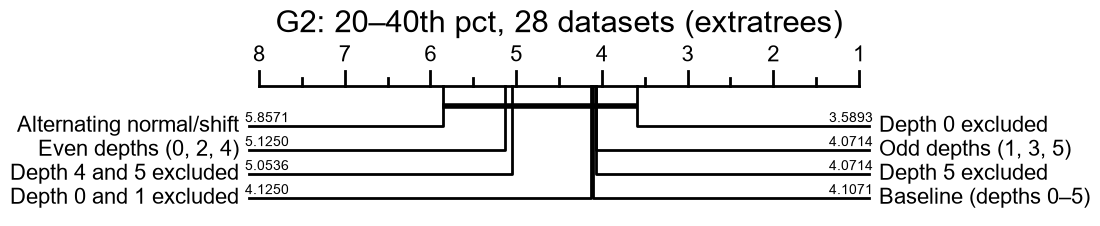

<StringArray>
['Alternating normal/shift', 'Baseline (depths 0–5)', 'Depth 0 and 1 excluded', 'Depth 0 excluded', 'Depth 4 and 5 excluded', 'Depth 5 excluded', 'Even depths (0, 2, 4)', 'Odd depths (1, 3, 5)']
Length: 8, dtype: str
Alternating normal/shift    2.0
Baseline (depths 0–5)       5.0
Depth 0 and 1 excluded      4.0
Depth 0 excluded            3.0
Depth 4 and 5 excluded      6.0
Depth 5 excluded            3.0
Even depths (0, 2, 4)       4.0
Odd depths (1, 3, 5)        0.0
dtype: float64
Depth 0 and 1 excluded      5.660714
Odd depths (1, 3, 5)        5.589286
Alternating normal/shift    4.767857
Even depths (0, 2, 4)       4.696429
Depth 0 excluded            4.446429
Depth 4 and 5 excluded      4.053571
Depth 5 excluded            3.714286
Baseline (depths 0–5)       3.071429
dtype: float64
('Baseline (depths 0–5)', 'Odd depths (1, 3, 5)', np.float64(0.00016395879031805527), True)
('Depth 0 and 1 excluded', 'Depth 0 excluded', np.float64(0.000514930121350876), True)
('Baseli

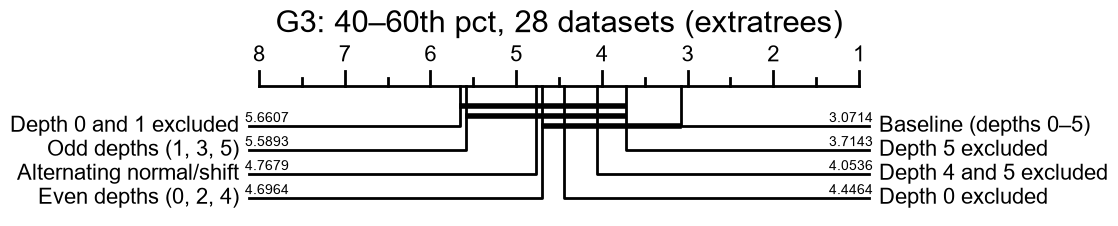

<StringArray>
['Alternating normal/shift', 'Baseline (depths 0–5)', 'Depth 0 and 1 excluded', 'Depth 0 excluded', 'Depth 4 and 5 excluded', 'Depth 5 excluded', 'Even depths (0, 2, 4)', 'Odd depths (1, 3, 5)']
Length: 8, dtype: str
Alternating normal/shift    2.0
Baseline (depths 0–5)       2.0
Depth 0 and 1 excluded      3.0
Depth 0 excluded            3.0
Depth 4 and 5 excluded      8.0
Depth 5 excluded            2.0
Even depths (0, 2, 4)       4.0
Odd depths (1, 3, 5)        2.0
dtype: float64
Depth 0 and 1 excluded      6.053571
Odd depths (1, 3, 5)        5.750000
Alternating normal/shift    5.232143
Depth 0 excluded            4.375000
Even depths (0, 2, 4)       3.892857
Baseline (depths 0–5)       3.714286
Depth 4 and 5 excluded      3.517857
Depth 5 excluded            3.464286
dtype: float64
('Baseline (depths 0–5)', 'Odd depths (1, 3, 5)', np.float64(7.204711437225342e-05), True)
('Depth 0 and 1 excluded', 'Depth 0 excluded', np.float64(0.00014962695558789352), True)
('Basel

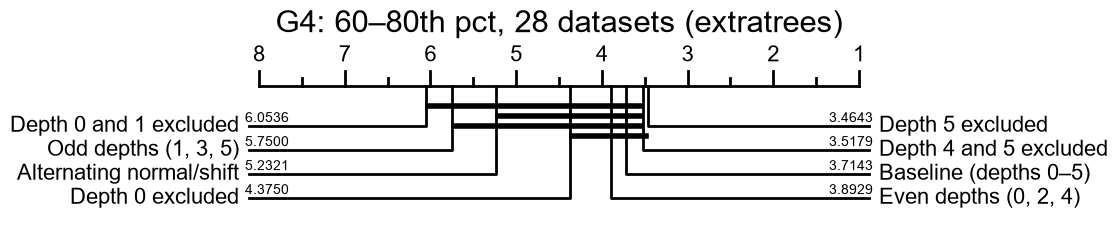

<StringArray>
['Alternating normal/shift', 'Baseline (depths 0–5)', 'Depth 0 and 1 excluded', 'Depth 0 excluded', 'Depth 4 and 5 excluded', 'Depth 5 excluded', 'Even depths (0, 2, 4)', 'Odd depths (1, 3, 5)']
Length: 8, dtype: str
Alternating normal/shift    3.0
Baseline (depths 0–5)       3.0
Depth 0 and 1 excluded      3.0
Depth 0 excluded            5.0
Depth 4 and 5 excluded      9.0
Depth 5 excluded            6.0
Even depths (0, 2, 4)       0.0
Odd depths (1, 3, 5)        0.0
dtype: float64
Odd depths (1, 3, 5)        5.793103
Depth 0 and 1 excluded      5.310345
Alternating normal/shift    5.241379
Even depths (0, 2, 4)       4.724138
Depth 0 excluded            4.379310
Depth 4 and 5 excluded      4.344828
Baseline (depths 0–5)       3.293103
Depth 5 excluded            2.913793
dtype: float64
('Baseline (depths 0–5)', 'Odd depths (1, 3, 5)', np.float64(2.60770320892334e-07), True)
('Depth 5 excluded', 'Odd depths (1, 3, 5)', np.float64(7.577240467071533e-06), True)
('Baseline 

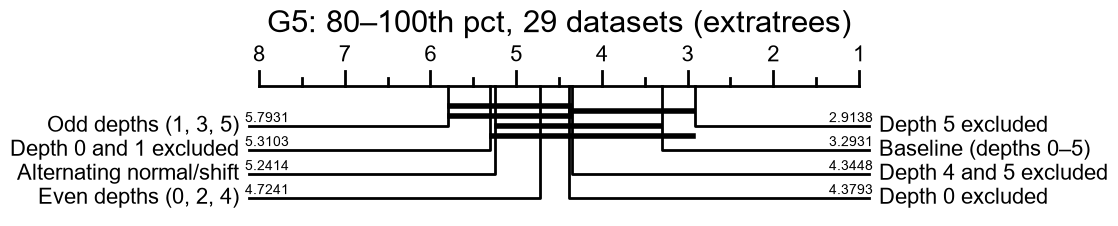

<StringArray>
['Alternating normal/shift', 'Baseline (depths 0–5)', 'Depth 0 and 1 excluded', 'Depth 0 excluded', 'Depth 4 and 5 excluded', 'Depth 5 excluded', 'Even depths (0, 2, 4)', 'Odd depths (1, 3, 5)']
Length: 8, dtype: str
Alternating normal/shift    1.0
Baseline (depths 0–5)       6.0
Depth 0 and 1 excluded      6.0
Depth 0 excluded            5.0
Depth 4 and 5 excluded      6.0
Depth 5 excluded            2.0
Even depths (0, 2, 4)       2.0
Odd depths (1, 3, 5)        4.0
dtype: float64
Alternating normal/shift    5.531250
Odd depths (1, 3, 5)        5.125000
Even depths (0, 2, 4)       4.890625
Depth 4 and 5 excluded      4.734375
Depth 0 and 1 excluded      4.375000
Depth 5 excluded            3.890625
Baseline (depths 0–5)       3.765625
Depth 0 excluded            3.687500
dtype: float64
('Alternating normal/shift', 'Baseline (depths 0–5)', np.float64(0.0025649620220065117), False)
('Alternating normal/shift', 'Depth 5 excluded', np.float64(0.0033791903406381607), False)


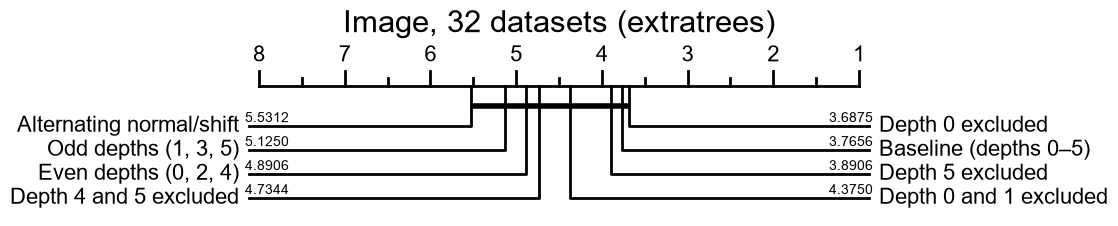

<StringArray>
['Alternating normal/shift', 'Baseline (depths 0–5)', 'Depth 0 and 1 excluded', 'Depth 0 excluded', 'Depth 4 and 5 excluded', 'Depth 5 excluded', 'Even depths (0, 2, 4)', 'Odd depths (1, 3, 5)']
Length: 8, dtype: str
Alternating normal/shift    2.0
Baseline (depths 0–5)       4.0
Depth 0 and 1 excluded      7.0
Depth 0 excluded            1.0
Depth 4 and 5 excluded      4.0
Depth 5 excluded            3.0
Even depths (0, 2, 4)       2.0
Odd depths (1, 3, 5)        1.0
dtype: float64
Depth 0 and 1 excluded      5.481481
Alternating normal/shift    5.425926
Odd depths (1, 3, 5)        5.203704
Depth 0 excluded            4.370370
Depth 4 and 5 excluded      4.351852
Even depths (0, 2, 4)       4.166667
Depth 5 excluded            3.685185
Baseline (depths 0–5)       3.314815
dtype: float64
('Alternating normal/shift', 'Baseline (depths 0–5)', np.float64(6.331503391265869e-05), True)
('Baseline (depths 0–5)', 'Odd depths (1, 3, 5)', np.float64(0.00035975796946169445), True)


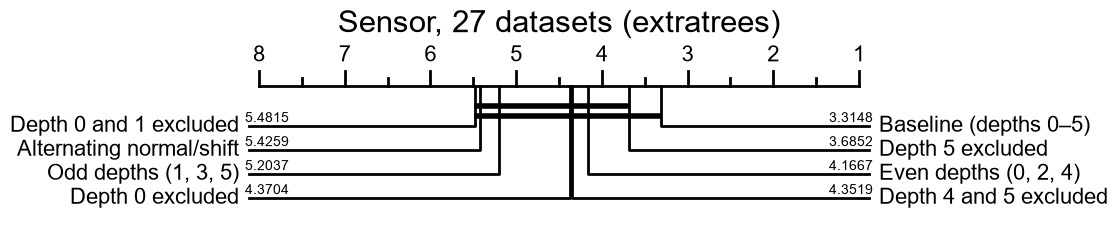

<StringArray>
['Alternating normal/shift', 'Baseline (depths 0–5)', 'Depth 0 and 1 excluded', 'Depth 0 excluded', 'Depth 4 and 5 excluded', 'Depth 5 excluded', 'Even depths (0, 2, 4)', 'Odd depths (1, 3, 5)']
Length: 8, dtype: str
Alternating normal/shift    1.0
Baseline (depths 0–5)       0.0
Depth 0 and 1 excluded      0.0
Depth 0 excluded            3.0
Depth 4 and 5 excluded      5.0
Depth 5 excluded            2.0
Even depths (0, 2, 4)       1.0
Odd depths (1, 3, 5)        2.0
dtype: float64
Depth 0 and 1 excluded      6.647059
Odd depths (1, 3, 5)        5.205882
Alternating normal/shift    5.147059
Depth 0 excluded            4.382353
Even depths (0, 2, 4)       4.352941
Baseline (depths 0–5)       3.617647
Depth 4 and 5 excluded      3.500000
Depth 5 excluded            3.147059
dtype: float64
('Depth 0 and 1 excluded', 'Depth 5 excluded', np.float64(0.001085997696644078), True)
('Baseline (depths 0–5)', 'Depth 0 and 1 excluded', np.float64(0.0017768989945419805), True)
('Depth

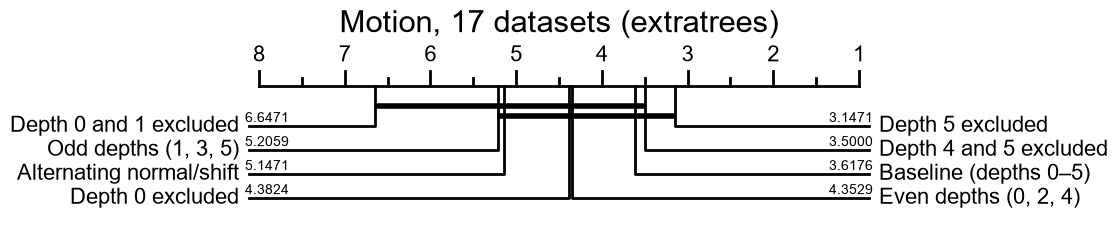

<StringArray>
['Alternating normal/shift', 'Baseline (depths 0–5)', 'Depth 0 and 1 excluded', 'Depth 0 excluded', 'Depth 4 and 5 excluded', 'Depth 5 excluded', 'Even depths (0, 2, 4)', 'Odd depths (1, 3, 5)']
Length: 8, dtype: str
Alternating normal/shift    1.0
Baseline (depths 0–5)       0.0
Depth 0 and 1 excluded      0.0
Depth 0 excluded            2.0
Depth 4 and 5 excluded      4.0
Depth 5 excluded            0.0
Even depths (0, 2, 4)       2.0
Odd depths (1, 3, 5)        0.0
dtype: float64
Depth 0 and 1 excluded      6.888889
Odd depths (1, 3, 5)        5.888889
Depth 0 excluded            5.000000
Alternating normal/shift    4.333333
Baseline (depths 0–5)       3.833333
Depth 5 excluded            3.777778
Even depths (0, 2, 4)       3.444444
Depth 4 and 5 excluded      2.833333
dtype: float64
('Baseline (depths 0–5)', 'Depth 0 and 1 excluded', np.float64(0.0078125), False)
('Depth 0 and 1 excluded', 'Depth 0 excluded', np.float64(0.01171875), False)
('Depth 0 and 1 excluded', 

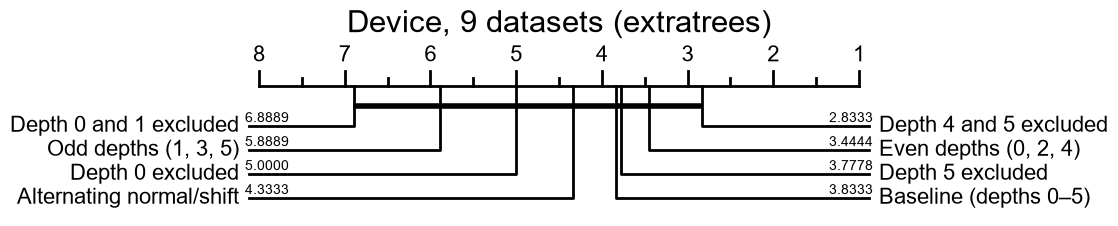

<StringArray>
['Alternating normal/shift', 'Baseline (depths 0–5)', 'Depth 0 and 1 excluded', 'Depth 0 excluded', 'Depth 4 and 5 excluded', 'Depth 5 excluded', 'Even depths (0, 2, 4)', 'Odd depths (1, 3, 5)']
Length: 8, dtype: str
Alternating normal/shift    3.0
Baseline (depths 0–5)       0.0
Depth 0 and 1 excluded      0.0
Depth 0 excluded            0.0
Depth 4 and 5 excluded      2.0
Depth 5 excluded            1.0
Even depths (0, 2, 4)       0.0
Odd depths (1, 3, 5)        1.0
dtype: float64
Depth 0 and 1 excluded      6.625
Odd depths (1, 3, 5)        4.750
Even depths (0, 2, 4)       4.750
Depth 0 excluded            4.500
Baseline (depths 0–5)       4.375
Alternating normal/shift    4.250
Depth 5 excluded            3.500
Depth 4 and 5 excluded      3.250
dtype: float64
('Alternating normal/shift', 'Depth 0 and 1 excluded', np.float64(0.0390625), False)
('Alternating normal/shift', 'Even depths (0, 2, 4)', np.float64(0.0390625), False)
('Baseline (depths 0–5)', 'Depth 0 and 1 e

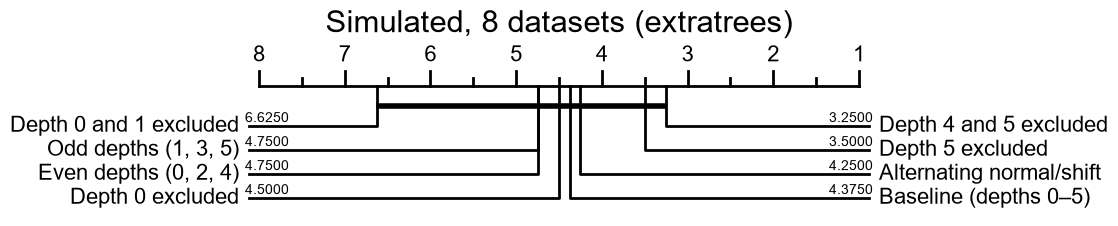

<StringArray>
['Alternating normal/shift', 'Baseline (depths 0–5)', 'Depth 0 and 1 excluded', 'Depth 0 excluded', 'Depth 4 and 5 excluded', 'Depth 5 excluded', 'Even depths (0, 2, 4)', 'Odd depths (1, 3, 5)']
Length: 8, dtype: str
Alternating normal/shift    0.0
Baseline (depths 0–5)       0.0
Depth 0 and 1 excluded      0.0
Depth 0 excluded            3.0
Depth 4 and 5 excluded      0.0
Depth 5 excluded            1.0
Even depths (0, 2, 4)       1.0
Odd depths (1, 3, 5)        2.0
dtype: float64
Depth 4 and 5 excluded      6.875
Even depths (0, 2, 4)       5.750
Alternating normal/shift    5.375
Depth 5 excluded            4.375
Odd depths (1, 3, 5)        4.125
Baseline (depths 0–5)       3.500
Depth 0 and 1 excluded      3.500
Depth 0 excluded            2.500
dtype: float64
('Depth 4 and 5 excluded', 'Depth 5 excluded', np.float64(0.0078125), False)
('Alternating normal/shift', 'Depth 0 and 1 excluded', np.float64(0.015625), False)
('Alternating normal/shift', 'Depth 0 excluded', n

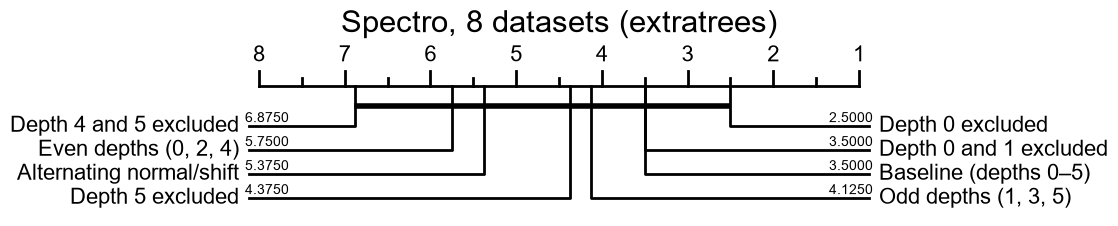

Skipping ECG (extratrees): only 6 datasets (MIN_DATASETS_PER_GROUP = 8).
<StringArray>
['Alternating normal/shift', 'Baseline (depths 0–5)', 'Depth 0 and 1 excluded', 'Depth 0 excluded', 'Depth 4 and 5 excluded', 'Depth 5 excluded', 'Even depths (0, 2, 4)', 'Odd depths (1, 3, 5)']
Length: 8, dtype: str
Alternating normal/shift    1.0
Baseline (depths 0–5)       2.0
Depth 0 and 1 excluded      2.0
Depth 0 excluded            0.0
Depth 4 and 5 excluded      5.0
Depth 5 excluded            3.0
Even depths (0, 2, 4)       0.0
Odd depths (1, 3, 5)        1.0
dtype: float64
Odd depths (1, 3, 5)        5.75000
Depth 0 and 1 excluded      5.56250
Depth 0 excluded            5.12500
Even depths (0, 2, 4)       4.71875
Alternating normal/shift    4.28125
Depth 4 and 5 excluded      4.25000
Baseline (depths 0–5)       3.34375
Depth 5 excluded            2.96875
dtype: float64
('Baseline (depths 0–5)', 'Odd depths (1, 3, 5)', np.float64(0.004759895644213269), False)
('Depth 5 excluded', 'Odd depth

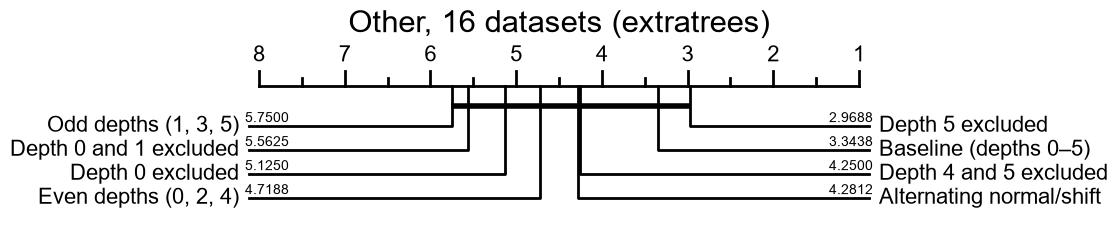

<StringArray>
['Alternating normal/shift', 'Baseline (depths 0–5)', 'Depth 0 and 1 excluded', 'Depth 0 excluded', 'Depth 4 and 5 excluded', 'Depth 5 excluded', 'Even depths (0, 2, 4)', 'Odd depths (1, 3, 5)']
Length: 8, dtype: str
Alternating normal/shift    2.0
Baseline (depths 0–5)       1.0
Depth 0 and 1 excluded      5.0
Depth 0 excluded            2.0
Depth 4 and 5 excluded      3.0
Depth 5 excluded            3.0
Even depths (0, 2, 4)       3.0
Odd depths (1, 3, 5)        0.0
dtype: float64
Odd depths (1, 3, 5)        5.947368
Alternating normal/shift    5.605263
Depth 0 and 1 excluded      4.947368
Even depths (0, 2, 4)       4.421053
Depth 4 and 5 excluded      4.157895
Depth 0 excluded            4.131579
Baseline (depths 0–5)       3.684211
Depth 5 excluded            3.105263
dtype: float64
('Baseline (depths 0–5)', 'Odd depths (1, 3, 5)', np.float64(0.001171112060546875), True)
('Depth 5 excluded', 'Odd depths (1, 3, 5)', np.float64(0.002399444580078125), False)
('Depth 0 e

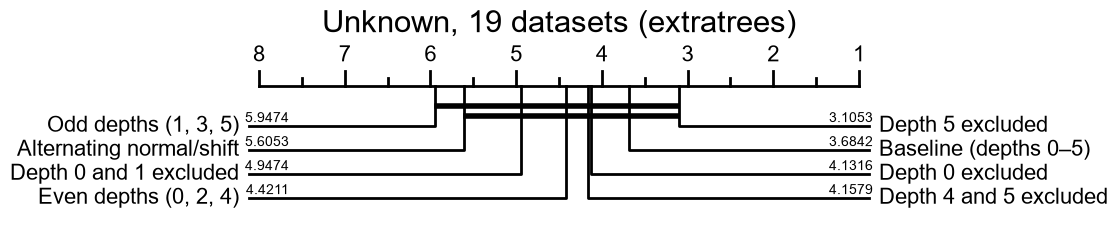

In [34]:
# CD diagram for each dataset-size group and each dataset type: all configurations, ranked within the group.
for grouping, (col, order) in GROUPINGS.items():
    for clf in classifiers:
        for group in order:
            in_group = table[(table["classifier"] == clf) & (table[col] == group)]
            n_ds = in_group["dataset"].nunique()
            short = re.split(r"\s{2}\(|\s\(n=", group)[0]          # "G1: 0–20th pct" or "Image"
            if n_ds < MIN_DATASETS_PER_GROUP:
                print(f"Skipping {short} ({clf}): only {n_ds} datasets (MIN_DATASETS_PER_GROUP = {MIN_DATASETS_PER_GROUP}).")
                continue
            df_perf = (
                in_group.rename(columns={"configuration": "classifier_name", "dataset": "dataset_name"})
                [["classifier_name", "dataset_name", "accuracy"]]
            )
            slug = re.sub(r"\W+", "_", short).strip("_")
            try:
                draw_cd_diagram(
                    df_perf=df_perf, alpha=CD_ALPHA, title=f"{short}, {n_ds} datasets ({clf})", labels=True,
                    filename=FIG_DIR / f"cd_{clf}_{col}_{slug}.png",
                )
            except RuntimeError as err:                             # Friedman test not significant in this group
                print(f"No diagram for {short} ({clf}): {err}")

### 9b. Datasets significantly different from the baseline (dataset by dataset)

For **each dataset** and each configuration, the baseline and the configuration are compared on the *same resamples* (paired), using the per-resample accuracies, and the datasets with a significant difference are counted. This is a per-dataset test, not a test across datasets.

- `PER_DATASET_TEST = "ttest"` is a paired t-test over the resamples. `"wilcoxon"` is the signed-rank test, but with **5 resamples its smallest possible two-sided p-value is 0.0625, so it can never be significant**; use it only with 6+ resamples (the `run.py` default is 30).
- Resamples share training data, so the variance is underestimated and p-values come out somewhat too small. Treat the counts as indicative, and prefer more resamples.
- Testing many datasets inflates false positives: at α = 0.05 about 5% of datasets are expected to come out "significant" by chance. The **BH-adjusted** columns control the false discovery rate across datasets and are the more trustworthy count.
- Identical differences in every resample give a t-test p-value of 0 (zero variance). For near-ceiling datasets check the size of the difference before counting it.

In [35]:
ALPHA = 0.05
PER_DATASET_TEST = "ttest"       # "ttest" or "wilcoxon"

def bh_adjust(p):
    # Benjamini-Hochberg adjusted p-values (false discovery rate)
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    scaled = p[order] * len(p) / np.arange(1, len(p) + 1)
    adjusted = np.minimum.accumulate(scaled[::-1])[::-1]
    out = np.empty(len(p))
    out[order] = np.minimum(adjusted, 1.0)
    return out

# One row per classifier x dataset x resample, one column per configuration (complete resample sets only).
wide = paired.pivot_table(index=["classifier", "dataset", "resample"], columns="configuration", values="accuracy")

rows = []
for (clf, ds), g in wide.groupby(level=["classifier", "dataset"]):
    for cfg in [c for c in wide.columns if c != BASELINE]:
        diff = (g[cfg] - g[BASELINE]).to_numpy()
        if len(diff) < 2 or np.allclose(diff, 0):
            p = 1.0                                   # identical results: no evidence of a difference
        elif PER_DATASET_TEST == "ttest":
            p = stats.ttest_rel(g[cfg], g[BASELINE]).pvalue
        else:
            p = stats.wilcoxon(diff).pvalue
        rows.append({"classifier": clf, "dataset": ds, "configuration": cfg, "n_resamples": len(diff),
                     "mean_diff_pp": 100 * diff.mean(), "p_value": 1.0 if np.isnan(p) else p})

per_dataset = pd.DataFrame(rows)
if PER_DATASET_TEST == "wilcoxon" and per_dataset["n_resamples"].min() < 6:
    print("WARNING: with fewer than 6 resamples a Wilcoxon test cannot reach p < 0.05; use 'ttest' or more resamples.")

per_dataset["p_adj_bh"] = per_dataset.groupby(["classifier", "configuration"])["p_value"].transform(bh_adjust)
per_dataset["sig"] = per_dataset["p_value"] < ALPHA
per_dataset["sig_bh"] = per_dataset["p_adj_bh"] < ALPHA
for grouping, (col, order) in GROUPINGS.items():
    per_dataset[col] = pd.Categorical(per_dataset["dataset"].map(dataset_groups[col]), categories=order, ordered=True)

def count_significant(frame, keys):
    rows = []
    for key, g in frame.groupby(keys, observed=True):
        key = key if isinstance(key, tuple) else (key,)
        rows.append({
            **dict(zip(keys, key)),
            "datasets": len(g),
            "better (p<α)": int((g["sig"] & (g["mean_diff_pp"] > 0)).sum()),
            "worse (p<α)": int((g["sig"] & (g["mean_diff_pp"] < 0)).sum()),
            "not significant": int((~g["sig"]).sum()),
            "better (BH)": int((g["sig_bh"] & (g["mean_diff_pp"] > 0)).sum()),
            "worse (BH)": int((g["sig_bh"] & (g["mean_diff_pp"] < 0)).sum()),
            "expected by chance": round(ALPHA * len(g), 1),
        })
    return pd.DataFrame(rows).set_index(keys)

print(f"Datasets with a significant difference from '{BASELINE}' ({PER_DATASET_TEST}, alpha = {ALPHA}):")
display(count_significant(per_dataset, ["classifier", "configuration"]))
for grouping, (col, order) in GROUPINGS.items():
    print(f"\nBy {grouping}:")
    display(count_significant(per_dataset, ["classifier", "configuration", col]))

print("\nDatasets that remain significant after BH correction:")
display(
    per_dataset.loc[per_dataset["sig_bh"], ["classifier", "configuration", "dataset", "size_group", "type_group",
                                            "mean_diff_pp", "p_value", "p_adj_bh"]]
    .sort_values(["classifier", "configuration", "p_adj_bh"]).round(4)
)

Datasets with a significant difference from 'Baseline (depths 0–5)' (ttest, alpha = 0.05):


datasets  better (p<α)  worse (p<α)  not significant  better (BH)  worse (BH)  expected by chance
classifier configuration                                                                                                              
extratrees Alternating normal/shift       142             9           54               79            8          47                 7.1
           Depth 0 and 1 excluded         142            11           63               68            8          55                 7.1
           Depth 0 excluded               142            10           37               95            6          29                 7.1
           Depth 4 and 5 excluded         142            26           41               75           22          35                 7.1
           Depth 5 excluded               142            17           18              107           11          12                 7.1
           Even depths (0, 2, 4)          142             9           48               85            6          39                 7.1
           Odd depths (1, 3, 5)           142             3           69               70            3          64                 7.1


By size group:


datasets  better (p<α)  worse (p<α)  not significant  better (BH)  worse (BH)  expected by chance
classifier configuration            size_group                                                                                                                                    
extratrees Alternating normal/shift G1: 0–20th pct  (size 0.00977–0.0582, n=29)        29             2            6               21            1           6                 1.5
                                    G2: 20–40th pct  (size 0.0587–0.08, n=28)          28             1           10               17            1           8                 1.4
                                    G3: 40–60th pct  (size 0.0836–0.134, n=28)         28             1           12               15            1           9                 1.4
                                    G4: 60–80th pct  (size 0.135–0.207, n=28)          28             2           11               15            2          10                 1.4
                                    G5: 80–100th pct  (size 0.239–1.76, n=29)          29             3           15               11            3          14                 1.5
           Depth 0 and 1 excluded   G1: 0–20th pct  (size 0.00977–0.0582, n=29)        29             5           13               11            4          11                 1.5
                                    G2: 20–40th pct  (size 0.0587–0.08, n=28)          28             1            5               22            1           4                 1.4
                                    G3: 40–60th pct  (size 0.0836–0.134, n=28)         28             2           15               11            2          13                 1.4
                                    G4: 60–80th pct  (size 0.135–0.207, n=28)          28             2           15               11            1          15                 1.4
                                    G5: 80–100th pct  (size 0.239–1.76, n=29)          29             1           15               13            0          12                 1.5
           Depth 0 excluded         G1: 0–20th pct  (size 0.00977–0.0582, n=29)        29             4            6               19            2           5                 1.5
                                    G2: 20–40th pct  (size 0.0587–0.08, n=28)          28             2            3               23            1           2                 1.4
                                    G3: 40–60th pct  (size 0.0836–0.134, n=28)         28             2            9               17            1           6                 1.4
                                    G4: 60–80th pct  (size 0.135–0.207, n=28)          28             1           10               17            1           9                 1.4
                                    G5: 80–100th pct  (size 0.239–1.76, n=29)          29             1            9               19            1           7                 1.5
           Depth 4 and 5 excluded   G1: 0–20th pct  (size 0.00977–0.0582, n=29)        29             2           10               17            1           7                 1.5
                                    G2: 20–40th pct  (size 0.0587–0.08, n=28)          28             0            7               21            0           7                 1.4
                                    G3: 40–60th pct  (size 0.0836–0.134, n=28)         28             5            9               14            5           8                 1.4
                                    G4: 60–80th pct  (size 0.135–0.207, n=28)          28             9            6               13            7           5                 1.4
                                    G5: 80–100th pct  (size 0.239–1.76, n=29)          29            10            9               10            9           8                 1.5
           Depth 5 excluded         G1: 0–20th pct  (size 0.00977–0.0582, n=29)        29             2            2               25          


By dataset type:


datasets  better (p<α)  worse (p<α)  not significant  better (BH)  worse (BH)  expected by chance
classifier configuration            type_group                                                                                                        
extratrees Alternating normal/shift Image (n=32)           32             1           16               15            1          15                 1.6
                                    Sensor (n=27)          27             2           12               13            2          11                 1.4
                                    Motion (n=17)          17             1            7                9            0           6                 0.9
                                    Device (n=9)            9             1            1                7            1           1                 0.5
                                    Simulated (n=8)         8             2            1                5            2           1                 0.4
...                                                       ...           ...          ...              ...          ...         ...                 ...
           Odd depths (1, 3, 5)     Simulated (n=8)         8             1            3                4            1           3                 0.4
                                    Spectro (n=8)           8             0            2                6            0           2                 0.4
                                    ECG (n=6)               6             0            3                3            0           3                 0.3
                                    Other (n=16)           16             0           11                5            0          11                 0.8
                                    Unknown (n=19)         19             1            8               10            1           8                 1.0

[63 rows x 7 columns]


Datasets that remain significant after BH correction:


,classifier,configuration,dataset,size_group,type_group,mean_diff_pp,p_value,p_adj_bh
189,extratrees,Alternating normal/shift,Crop,"G4: 60–80th pct (size 0.135–0.207, n=28)",Image (n=32),-0.9030,0.0000,0.0000
126,extratrees,Alternating normal/shift,ChlorineConcentration,"G3: 40–60th pct (size 0.0836–0.134, n=28)",Sensor (n=27),-0.9080,0.0000,0.0000
14,extratrees,Alternating normal/shift,AconityMINIPrinterSmall_eq,"G4: 60–80th pct (size 0.135–0.207, n=28)",Unknown (n=19),-0.8904,0.0000,0.0000
623,extratrees,Alternating normal/shift,NonInvasiveFetalECGThorax1,"G5: 80–100th pct (size 0.239–1.76, n=29)",ECG (n=6),-0.5276,0.0000,0.0000
322,extratrees,Alternating normal/shift,FacesUCR,"G2: 20–40th pct (size 0.0587–0.08, n=28)",Image (n=32),-0.9984,0.0000,0.0000
...,...,...,...,...,...,...,...,...
741,extratrees,"Odd depths (1, 3, 5)",ProximalPhalanxTW,"G2: 20–40th pct (size 0.0587–0.08, n=28)",Image (n=32),0.4878,0.0202,0.0468
370,extratrees,"Odd depths (1, 3, 5)",FordA,"G5: 80–100th pct (size 0.239–1.76, n=29)",Sensor (n=27),-0.1490,0.0225,0.0494
930,extratrees,"Odd depths (1, 3, 5)",UWaveGestureLibraryAll,"G5: 80–100th pct (size 0.239–1.76, n=29)",Motion (n=17),-0.1005,0.0226,0.0494
377,extratrees,"Odd depths (1, 3, 5)",FordB,"G5: 80–100th pct (size 0.239–1.76, n=29)",Sensor (n=27),-0.2222,0.0232,0.0500


# Analysis

As stated at the start of the notebook, the most promising tests are those that remove depths 5 (called $QUANT^{FAST}$ in the original paper), depths 4 and 5 and that only kept even depths. First, we will briefly clarify why the other experiments were disregarded.

## Removing early depths

Initial tests included removing depth 0 depth 0 and 1 intervals from feature extraction. The initial hypothesis was that such high level intervals (only 1 and 3 intevals respectively) is too substantial of a generalisation, and doesn't capture any of the original datasets shape.

Early testing proved these experiments to be worse than the original experiments overall. [EXPLAIN HOW]

These tests seem to prove the usefulness of longer intervals. Particularly, information provided by interval 0 essential serves as a summarisation of the entire sample, representing the median along with other upper and lower quantiles, which provide a good description of the overall distribution of the dataset. This early depth information has proven to be important across most datasets.

## Alternating depths, odd depths and even depths

These tests included only taking intervals at odd depth values (1, 3, 5), even depth values (0, 2, 4) and alternating between taking normal depth intervals (0, 2, 4) and shift depth intervals (1, 3, 5). The intial hypothesis of taking intervals in this way was that data represented by the removed depths could be represented by the depths above and below to enough of a degree to maintain accuracy while reducing the features needed.

Early experiments with only even depths proved to be beneficial overall, maintaining a reasonable level of accuracy while resulting in a substantial reduction in training time and feature count. [EXPLAIN HOW]

This method may have performed well overall since it maintained enough depth information to fairly represent the depths that were removed, while removing lower depths (3 and 5), which carry a substantial number of features compared to others.

Early tests with alternating depths proved the performance of this method to be reasonable, but was out performed by both the baseline performance and other experiment configuations. [EXPLAIN HOW]

This method may have suffered due to the removal of relational information between original and shifted intervals at each depth. Shifted intervals have the same length as normal intervals at each depth, so the model may be able to use this relationship to better understand the shape of the dataset.

Experimentation with only odd depths was conducted after the success of experimentation with even depths (0, 2, 4). However, this method resulted in reduced overall performance compared experimentation with even depths taken. [EXPLAIN HOW]

This method likely suffered in terms of accuracy compared to even depths experimenation due to the importance of the depths that were removed. Intial experimentation has already demonstrated the importance of depth 0 information (with its removal resulting in more substantial performance drop compared to later depth removal), and that depth 5 information is less relevant than other levels (indicated by the original papers $QUANT^{FAST}$ and our own no depth 5 experiment), meaning this implementation removes a highly relevant level while keeping a less relevant one. Even depths on the other had keeps depth 0, the more relevant depth, and removes depth 5, a less relevant level, likely resulting in its improved performance.

## Removing later depths

These experiments included removing depth 5 and depth 4 and 5 intervals from feature extraction. As stated previously, the removal of depth 5 only was done in the orginal quant paper, called $QUANT^{FAST}$, which was the main motivation behind this depth removal experimenation. The original paper indicated that performance gains reduced as lower depths were added, with substantially more features taken at each depth, which is why limiting the maximun depth to 6 (or 5 in the case of $QUANT^{FAST}$), was done. Specifically, this was the primary motivation for experimenting with the removal of depth 4 and 5, since the removal of later depths was suggested by the paper.

Removal of depth 5, as in $QUANT^{FAST}$, resulted in insignificant changes in accuracy overall while reducing feature and training times. [EXPLAIN HOW]

Removal of depts 4 and 5 resulted in a slight reduction in accuracy, but substantial gains in terms of training time and feature count reduction. [EXPLAIN HOW]

As previously mentioned, this is likely as a result of lower depths being less relavant compared to higher ones. 

It should also be once again noted that setting the depth value to 6, or in the case of these experiments 5 or 4, does not nessessarily mean that intervals will be taken at all of these depths. These depths represented the maximum depths intervals can be taken from, but in any case where $d = log_2 n + 1$ for a dataset with samples of length $n$ is lower than these maximun depths, intervals will only be taken to as maximum of depth $d$.


NEXT EXERIMENTS: SEE IF NO DEPTH 3 4 5 IS COMPARABLE AND EXPERIMENT WITH REMAINING SINGLE DEPTH REMOVALS (1, 2, 3, 4)

## Final results